# KQC DemoTwoface — the Demo chip split over two faces (flip chip) (Quantcore PDK rebuild)

**What the chip is.** KQCircuits' `chips/demo_twoface.py` (class `DemoTwoface`, default parameters, chip name
"DT"; © IQM Finland Oy, GPL-3.0, <https://github.com/iqm-finland/KQCircuits>; local copy
`third_party/KQCircuits/klayout_package/python/kqcircuits/chips/demo_twoface.py`; spec
`docs/designs/kqc/demo_twoface.md`). Four Swissmons on the bottom chip (face 0, `1t1`) at (2000 | 8000,
3200 | 6800) µm, with two straight buses (QB1–QB2, QB4–QB3; a = 4, b = 9 µm) and a charge and a flux line per
qubit from an ARD24 sample holder. Each readout leaves the qubit's coupler 1 on the bottom chip, crosses to the
top chip (face 1, `2b1`) through a flip-chip RF connector, meanders there and couples through a finger capacitor
and a T into one of two probe lines that also run on the top chip (probe line 1 serves QB1 and QB3, probe line 2
QB2 and QB4). The probe lines leave the top chip through an RF connector each way to the bottom-chip launchers.

This notebook **rebuilds** the chip with our components, routes, netlist and LOM on the Quantcore PDK — not a
replica. We distribute the rebuild under GPL-3.0.

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` on both faces (top-chip box (1500, 1500)–(8500, 8500) µm) | same 10 × 10 mm (ARD24 launchers on its edges); Quantcore die frame on the bottom chip only — PDK v3 defines no frame for the flip-chip top chip (its layers export to 800–804/0); device ID "DT" |
| launchers | ARD24, `launcher_indent` 680 µm (outer etch 21 µm from the edge) | ARD24, indent **759 µm** from the PDK pad rule (outer etch `frame.pad_edge` = 100 µm); same 12-pad assignment |
| substrate | silicon εr 11.45 (KQC simulation default) | sapphire 650 µm, εr 10.25 |
| junctions | KQC Manhattan SQUIDs (assumed 15–18 nH) | Quantcore trilayer SQUIDs **detuned on purpose** by the straight finger: 0.27 / 0.26 / 0.25 / 0.24 µm → R_n 41.7 / 43.3 / 45.0 / 46.9 kΩ (parallel), L_J 6.24 / 6.48 / 6.73 / 7.02 nH, so the bus-coupled pairs do not hybridise |
| cheese | KQC's whole-area ground grid (`with_grid`) | **the original wins:** KQC's grid (`with_grid=True`) on the bottom chip (face 0); the top chip gets none in this build (the Designer grids face 0 only) |
| elements, positions, routes | — | kept exactly; waypoints derived from the launcher ports |
| placement | centred | centred (checked, no shift) |

**Kept exactly (same KQC cells, parameters and positions):** the ARD24 launcher assignment (12 pads); the four
`Swissmon`s (coupler lengths 120 µm, port widths 4/10/4 µm) with KQC's rotation and mirror per qubit; the buses;
the charge lines (6 µm open end) and the flux lines (1500 µm past the launcher corner, then across); the readout
path (700 µm out of coupler 1, 400 µm sideways to the face change, 100 µm, then 1300 µm of meander on the top
chip) with the KQC total lengths 5000 … 5300 µm; the `FingerCapacitorSquare`s (7/6/5/4 fingers) and the
`WaveguideCoplanarSplitter` T's (lengths 11/11/41 µm) on the top chip; the `FingerCapacitorTaper` input
capacitors (4 and 6 fingers, 20 µm taper) 700 µm from the first T; the probe-line paths including their face
changes. The `FlipChipConnectorRf` cells are inserted by KQC's `WaveguideComposite` at the face-change nodes, as
in the source.

**Simplified:** the readout meanders are fitted by the router on the 1300 µm segment (KQC: a `Meander` with
`meanders=5` between the same two points; same length).

**Faces in the LOM and DRC:** the LOM is face-agnostic. The RF connector is part of its route, and the
capacitance of a line to the opposite chip comes only from a FEM C-matrix with both faces (the exported jobs).
The readouts end on a capacitor at both ends (coupler pad, finger capacitor), so they are λ/2 resonators
(≈ 11–12 GHz for 5 mm).

## 1 · Setup

`LIVE` follows `QCC_LIVE` (default on: KLayout opens and redraws after every change; `QCC_LIVE=0` for batch
runs). `RUN_FEM = False` keeps the FEM step at "export only"; `True` solves the jobs in a new batch AEDT
2024 R1 (if installed). `FULL_FAB = False` skips corner rounding of the grid holes in the fab step (`qcc mask` writes the full file).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.circuit.bridges import junction_from_fingers

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
RUN_FEM = False                                  # True: solve the exported jobs in a new batch AEDT 2024 R1
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc")               # design JSON + final snapshots
STEPS = Path("build/snapshots/demo_twoface")  # step-by-step snapshots (build/ is not kept in the repo)

## 2 · The PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**The junctions from the PDK rule.** KQC draws a SQUID in every Swissmon; here each becomes a Quantcore trilayer
SQUID whose straight finger is KQC's `junction_width` (bent finger 0.6 µm). The four qubits are **detuned** by
their straight fingers (0.27 … 0.24 µm), so the two bus-coupled pairs do not hybridise; all four parallel R_n are
in the 40–50 kΩ window. `junction_from_fingers` gives each SQUID's L_J and C_J for the LOM and the FEM ports.
`TOP` puts an element on the top chip (face 1, `2b1`).

In [4]:
WIDTHS = {"QB1": 0.27, "QB2": 0.26, "QB3": 0.25, "QB4": 0.24}
JJ_PARAMS = {n: {"junction_type": "Quantcore Squid", "junction_width": w} for n, w in WIDTHS.items()}
JUNCTION = {n: {"Lj_nH": round(j.lj_nH, 4), "Cj_fF": round(j.cj_fF, 3)}
            for n, j in ((n, junction_from_fingers(w, 0.6, n=2)) for n, w in WIDTHS.items())}
TOP = {"face_ids": ["2b1", "1t1"]}                         # an element on the top chip (face 1)
display(Markdown("| qubit | straight finger (µm) | L_J (nH) | C_J (fF) |\n|---|---|---|---|\n" + "\n".join(
    f"| {n} | {WIDTHS[n]} | {j['Lj_nH']} | {j['Cj_fF']} |" for n, j in JUNCTION.items())))

| qubit | straight finger (µm) | L_J (nH) | C_J (fF) |
|---|---|---|---|
| QB1 | 0.27 | 6.2356 | 16.2 |
| QB2 | 0.26 | 6.4754 | 15.6 |
| QB3 | 0.25 | 6.7344 | 15.0 |
| QB4 | 0.24 | 7.015 | 14.4 |

## 3 · The die and its frame

`Designer(...)` starts the chip: the 10 × 10 mm box, the ARD24 launchers with KQC's DemoTwoface assignment (pad
numbers clockwise from the top-left; only the assigned ones are drawn) and the chip name "DT" (the device ID).
`with_grid=True` asks for KQC's whole-area ground grid (the original's cheese; no PDK band is then added). The
PDK frame (dicing L's 1000/0, alignment grids 1001/0, boundary 100/0) is drawn on the bottom chip.

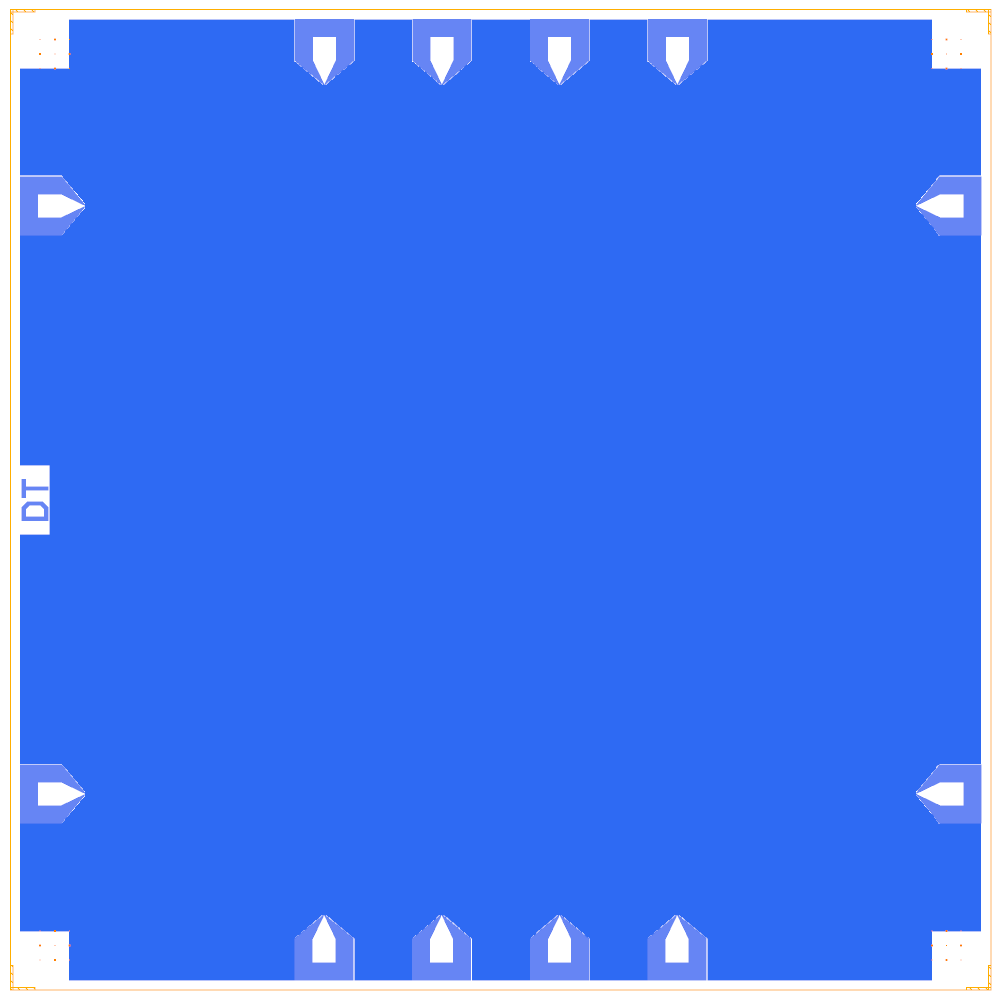

In [5]:
pads = {2: "FL-QB1", 3: "PL-1-IN", 4: "PL-2-IN", 5: "FL-QB2", 7: "DL-QB2", 12: "DL-QB4", 14: "FL-QB4",
        15: "PL-2-OUT", 16: "PL-1-OUT", 17: "FL-QB3", 19: "DL-QB3", 24: "DL-QB1"}
d = Designer("demo_twoface", box=(0, 0, 10000, 10000), launchers={"type": "ARD24", "assign": pads},
             chip={"name_chip": "DT", "with_grid": True}, live=LIVE)
L = {name: f"chip.{name}" for name in pads.values()}       # launcher ports, "chip.<name>"
snap(d, STEPS / "1_die.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420);

## 4 · Launchers and the pad rule

**PDK rule:** a launcher's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge. For ARD24 the
Designer sets `launcher_indent` = 100 + 240 (taper) + 240 (pad) + 179 (gap) = **759 µm** (KQC: 680). All routes
from launchers below take their waypoints from the launcher ports (`corner(L[...])`), so the 79 µm shift carries
through without other changes.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| chip.FL-QB1 | launcher port | n | port 759 µm in (indent from the rule) | ✓ |
| chip.PL-1-IN | launcher port | n | port 759 µm in (indent from the rule) | ✓ |
| chip.PL-2-IN | launcher port | n | port 759 µm in (indent from the rule) | ✓ |
| chip.FL-QB2 | launcher port | n | port 759 µm in (indent from the rule) | ✓ |
| chip.DL-QB2 | launcher port | e | port 759 µm in (indent from the rule) | ✓ |
| chip.DL-QB4 | launcher port | e | port 759 µm in (indent from the rule) | ✓ |
| chip.FL-QB4 | launcher port | s | port 759 µm in (indent from the rule) | ✓ |
| chip.PL-2-OUT | launcher port | s | port 759 µm in (indent from the rule) | ✓ |
| chip.PL-1-OUT | launcher port | s | port 759 µm in (indent from the rule) | ✓ |
| chip.FL-QB3 | launcher port | s | port 759 µm in (indent from the rule) | ✓ |
| chip.DL-QB3 | launcher port | w | port 759 µm in (indent from the rule) | ✓ |
| chip.DL-QB1 | launcher port | w | port 759 µm in (indent from the rule) | ✓ |

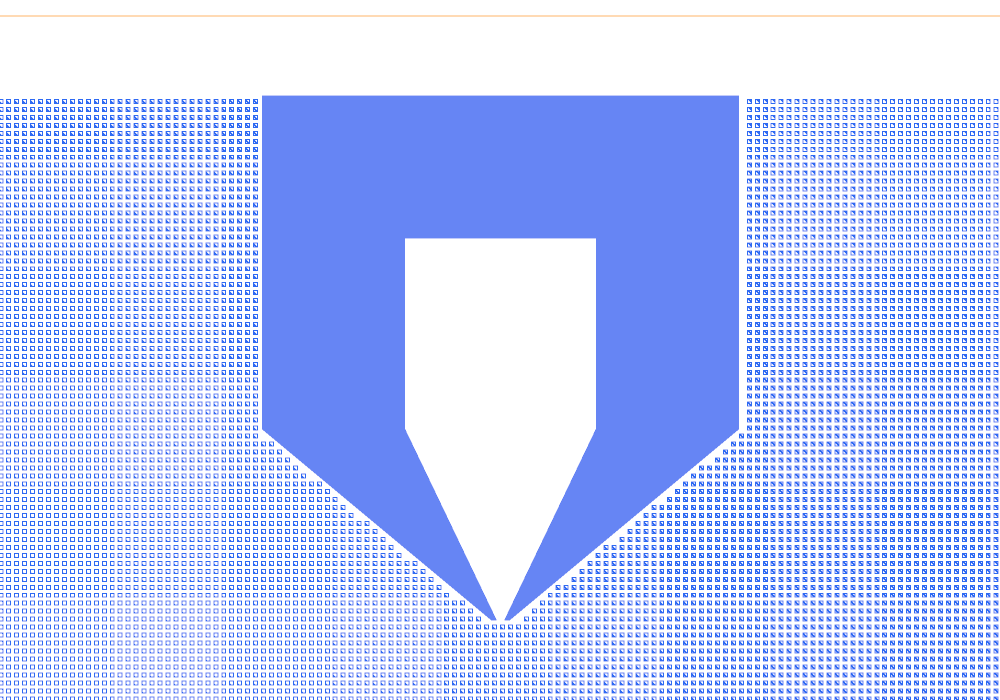

In [6]:
display(Markdown(pads_md(d)))
x, y = port_xy(d, L["PL-1-IN"])
snap(d, STEPS / "2_launcher.png", box=(x - 400, y - 100, x + 400, 10000 + 20), size=(1000, 700), width=420);

## 5 · Components

**Qubits (bottom chip).** Four `Swissmon`s at KQC's `DTrans(0, True, 2000, 6800)`, `DTrans(2, False, 8000,
6800)`, …: three 120 µm couplers, port widths 4/10/4 µm, the standard flux line. Ports `cplr0`–`cplr2`, `drive`,
`flux`.

**Readout capacitors and T's (top chip).** Per readout, KQC's chain: the finger capacitor (7/6/5/4 fingers)
placed by its port `a` at the meander end (700 µm out of coupler 1, then 500 µm sideways and 1300 µm further), the
probe-line T snapped by its `bottom` port to the capacitor's `b`. `add_aligned` places a cell by a port.

**Input capacitors (top chip).** A `FingerCapacitorTaper` (4 / 6 fingers, 20 µm taper) 700 µm above the first T
of each probe line.

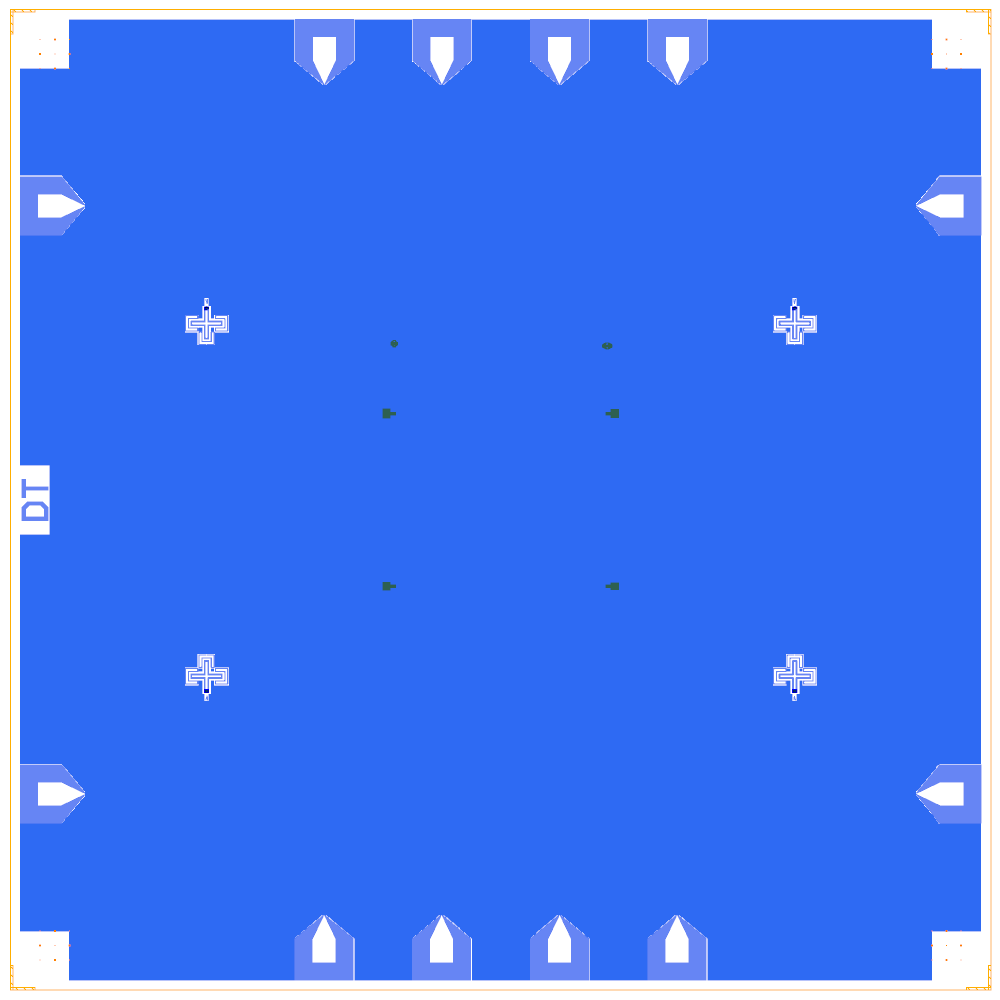

In [7]:
def xy(ref):                                     # absolute port position
    return port_xy(d, ref)


def corner(ref, dist=100.0):                     # KQC "<port>_corner": one turn radius out along the port
    x, y, a = port_info(d, ref)
    return (x + dist * math.cos(math.radians(a)), y + dist * math.sin(math.radians(a)))


base = {"QB1": (2000, 6800, 0, True), "QB2": (8000, 6800, 180, False),
        "QB3": (2000, 3200, 0, False), "QB4": (8000, 3200, 180, True)}
RR_PATH = {}
with d.batch():
    qb = {n: d.add(n, "Swissmon", at=(x, y), rot=r, mirror=m, cpl_length=[120, 120, 120], port_width=[4, 10, 4],
                   junction=JUNCTION[n], **JJ_PARAMS[n]) for n, (x, y, r, m) in base.items()}
    for i, mirrored, fingers in ((1, False, 7), (2, True, 6), (3, False, 5), (4, True, 4)):
        s = -1 if mirrored else 1
        p2 = shift_away(xy(f"QB{i}.cplr1"), base[f"QB{i}"][:2], 700)
        p3, p4 = (p2[0] + 400 * s, p2[1]), (p2[0] + 500 * s, p2[1])
        cap = add_aligned(d, f"C{i}", "FingerCapacitorSquare", "a", (p4[0] + 1300 * s, p4[1]),
                          rot=180 if mirrored else 0, finger_number=fingers, **TOP)
        d.add(f"PL{i}", "WaveguideCoplanarSplitter", snap="bottom", to=cap.b, lengths=[11, 11, 41],
              port_names=["right", "left", "bottom"], **TOP)
        RR_PATH[i] = (p2, p3, p4)
    for k, (qa, fingers) in enumerate(((1, 4), (2, 6)), start=1):
        lx, ly = xy(f"PL{qa}.left")
        d.add(f"CIN{k}", "FingerCapacitorTaper", at=(lx, ly + 700), rot=270, finger_number=fingers,
              taper_length=20, **TOP)                  # KQC: DTrans(3, False, T(a).left + (0, 700))
snap(d, STEPS / "3_components.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420);

## 6 · Routes

**Buses** (a = 4, b = 9 µm) straight between the side couplers 2 of QB1–QB2 and QB4–QB3. **Charge lines** (6 µm
open end) from the launcher corner; **flux lines** 1500 µm past the launcher corner, then across to the qubit.
**Readouts:** from coupler 1, 700 µm out, 400 µm sideways to a waypoint with `face_id="2b1"` (the face change:
KQC's `WaveguideComposite` inserts the `FlipChipConnectorRf` there), 100 µm, then a meander to the capacitor with
the KQC totals 5000 … 5300 µm.

In [8]:
lengths = {1: 5000, 2: 5100, 3: 5200, 4: 5300}
with d.batch():
    d.route("CPL12", qb["QB1"].cplr2, qb["QB2"].cplr2, a=4, b=9)
    d.route("CPL43", qb["QB4"].cplr2, qb["QB3"].cplr2, a=4, b=9)
    for i in range(1, 5):
        d.route(f"DL{i}", L[f"DL-QB{i}"], qb[f"QB{i}"].drive, nodes=[corner(L[f"DL-QB{i}"])], term2=6)
        cx, cy = corner(L[f"FL-QB{i}"])
        shift = 1500 if i in (3, 4) else -1500
        fx, _ = xy(f"QB{i}.flux")
        d.route(f"FL{i}", L[f"FL-QB{i}"], qb[f"QB{i}"].flux, nodes=[(cx, cy + shift), (fx, cy + shift)])
    for i in range(1, 5):
        p2, p3, p4 = RR_PATH[i]
        d.route(f"RR{i}", qb[f"QB{i}"].cplr1, f"C{i}.a", meander=lengths[i],
                nodes=[p2, d.waypoint(p3, face_id="2b1"), p4])

**Probe lines** (KQC `produce_probeline("PL-1", 1, 3, mirrored=True, 4)` and `("PL-2", 2, 4, False, 6)`): from
the input launcher 1000 µm along its corner, across to the T's x, down onto the top chip (face change 700 µm
above the input capacitor) → input capacitor → T(a) → T(b) on the top chip (`face_ids=["2b1"]`) → back down to
the bottom chip and out to the launcher. Each probe line drops onto the top chip *before* it passes over a bus, as
in KQC.

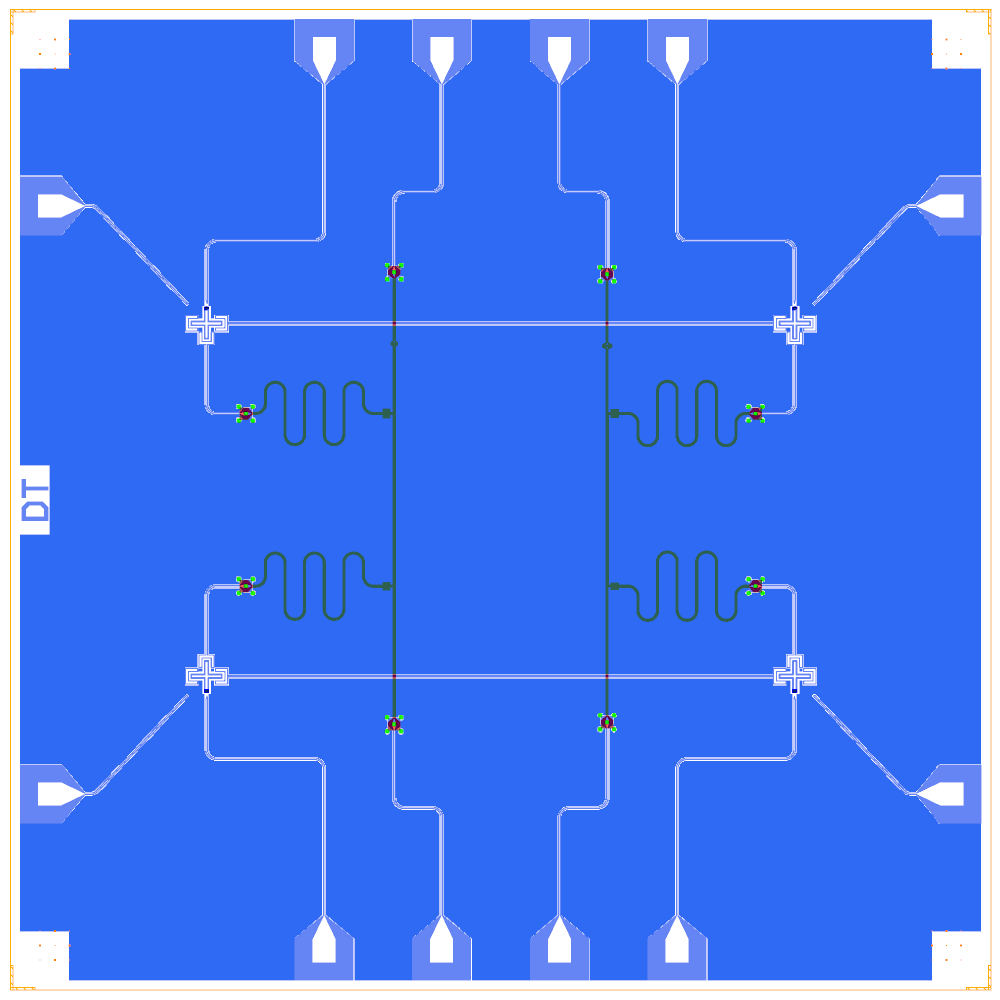

{'CPL12': 5562.0, 'CPL43': 5562.0, 'RR1': 5000.0, 'RR2': 5100.0, 'RR3': 5200.0, 'RR4': 5300.0, 'P1_in': 2897.7, 'P1_a': 668.5, 'P1_b': 1740.0, 'P1_out': 3629.2, 'P2_in': 2919.7, 'P2_a': 646.5, 'P2_b': 1740.0, 'P2_out': 3629.2}


In [9]:
with d.batch():
    for k, (pl, qa, qbn, mirrored) in enumerate((("PL-1", 1, 3, True), ("PL-2", 2, 4, False)), start=1):
        side1, side2 = ("left", "right") if mirrored else ("right", "left")
        lx, ly = xy(f"PL{qa}.left")
        ax, ay = xy(f"CIN{k}.a")
        cx, cy = corner(L[f"{pl}-IN"])
        d.route(f"P{k}_in", L[f"{pl}-IN"], f"CIN{k}.a",
                nodes=[(cx, cy - 1000), (lx, cy - 1000), d.waypoint((ax, ay + 700), face_id="2b1")])
        d.route(f"P{k}_a", f"CIN{k}.b", f"PL{qa}.{side1}", face_ids=["2b1"])
        d.route(f"P{k}_b", f"PL{qa}.{side2}", f"PL{qbn}.{side1}", face_ids=["2b1"])
        rx, ry = xy(f"PL{qbn}.right")
        ox, oy = corner(L[f"{pl}-OUT"])
        d.route(f"P{k}_out", L[f"{pl}-OUT"], f"PL{qbn}.{side2}",
                nodes=[(ox, oy + 1000), (rx, oy + 1000), d.waypoint((rx, ry - 1400), face_id="2b1")])
snap(d, STEPS / "4_routes.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420)
print({k: round(v, 1) for k, v in d.result.route_lengths().items() if k.startswith(("RR", "CPL", "P"))})

**Sim groups, centring, save.** A Q3D C-matrix job per qubit + readout + capacitor (300 µm margin; the box spans
both faces) and per bus-coupled pair. `center_in_die` confirms the content is centred (no shift); then
`demo_twoface.json` is saved.

In [10]:
for i in range(1, 5):
    d.sim_group(f"QB{i}_RR{i}", [f"QB{i}", f"RR{i}", f"C{i}"], margin_um=300, analyses=["q3d_cmatrix"])
d.sim_group("QB1_QB2", ["QB1", "QB2", "CPL12"], analyses=["q3d_cmatrix"])
d.sim_group("QB3_QB4", ["QB3", "QB4", "CPL43"], analyses=["q3d_cmatrix"])
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN = d.save(OUT / "demo_twoface.json")
print(d, "→", DESIGN)

centring shift (µm): (0.0, 0.0)


<Designer demo_twoface: 14 instances, 22 routes, live=False> → examples\designs\kqc\demo_twoface.json


## 7 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Here:** the warnings are each Swissmon's unused coupler 0, as in KQC. **No `crossing` errors:** each probe
line drops onto the top chip (face change at the RF connector, waypoint `face_id: "2b1"`) *before* it passes over
the bottom-chip bus (CPL12 at y = 6800, CPL43 at y = 3200); the crossing rule is face-aware, so these pairs on
different faces are not flagged (the last cell of step 14 checks the built geometry at all four points). No PDK
design warning: `pdk_rn` applies the 40–50 kΩ window to each SQUID's parallel R_n (41.7–46.9 kΩ).

In [11]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

**0 errors · 4 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 4 | QB1.cplr0 is not connected (no route or snap) |

| check | value |
|---|---|
| cheese | the original design's own (or none) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Squid × 4 |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

Swissmon → island node (C and SQUID to ground) and a node per used coupler; a straight bus between two coupler
pads is one conductor (the qubits couple capacitively through it; a wire in the LOM, not a resonator); a readout
between the coupler pad and the finger capacitor → λ/2 `TLres`; the T's and probe-line routes form one probe-line
node per line, between its input capacitor and the output launcher (50 Ω). Charge and flux lines are drive /
flux controls.

In [12]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**QB1's ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith("QB1."))))

**23 nodes · 66 branches · 8 controls · 4 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `QB1` | `QB1.island` |
| `QB1.cplr0` | `QB1.cplr0` |
| `QB1.cplr1` | `QB1.cplr1`, `C1.a` |
| `QB1.cplr2` | `QB1.cplr2`, `QB2.cplr2` |
| `QB2` | `QB2.island` |
| `QB2.cplr0` | `QB2.cplr0` |
| `QB2.cplr1` | `QB2.cplr1`, `C2.a` |
| `QB3` | `QB3.island` |
| `QB3.cplr0` | `QB3.cplr0` |
| `QB3.cplr1` | `QB3.cplr1`, `C3.a` |
| `QB3.cplr2` | `QB3.cplr2`, `QB4.cplr2` |
| `QB4` | `QB4.island` |
| `QB4.cplr0` | `QB4.cplr0` |
| `QB4.cplr1` | `QB4.cplr1`, `C4.a` |
| `C1.b` | `C1.b`, `PL1.t`, `C3.b`, `PL3.t`, `CIN1.b`, `chip.PL-1-OUT` |
| `C2.b` | `C2.b`, `PL2.t`, `C4.b`, `PL4.t`, `CIN2.b`, `chip.PL-2-OUT` |
| `CIN1.a` | `CIN1.a`, `chip.PL-1-IN` |
| `CIN2.a` | `CIN2.a`, `chip.PL-2-IN` |
| `chip.DL-QB1` | `chip.DL-QB1` |
| `chip.DL-QB2` | `chip.DL-QB2` |
| `chip.DL-QB3` | `chip.DL-QB3` |
| `chip.DL-QB4` | `chip.DL-QB4` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `C_QB1` | C | `QB1` – `gnd` | 78.4 fF |
| `J_QB1` | SQUID | `QB1` – `gnd` | Lj 6.24 nH, Cj 16.2 fF |
| `Cg_QB1_cplr0` | C | `QB1` – `QB1.cplr0` | 3.8 fF |
| `Cc_QB1_cplr0` | C | `QB1.cplr0` – `gnd` | 69.3 fF |
| `Cg_QB1_cplr1` | C | `QB1` – `QB1.cplr1` | 3.8 fF |
| `Cc_QB1_cplr1` | C | `QB1.cplr1` – `gnd` | 69.3 fF |
| `Cg_QB1_cplr2` | C | `QB1` – `QB1.cplr2` | 3.8 fF |
| `Cc_QB1_cplr2` | C | `QB1.cplr2` – `gnd` | 69.3 fF |
| `C_QB2` | C | `QB2` – `gnd` | 78.4 fF |
| `J_QB2` | SQUID | `QB2` – `gnd` | Lj 6.48 nH, Cj 15.6 fF |
| `Cg_QB2_cplr0` | C | `QB2` – `QB2.cplr0` | 3.8 fF |
| `Cc_QB2_cplr0` | C | `QB2.cplr0` – `gnd` | 69.3 fF |
| `Cg_QB2_cplr1` | C | `QB2` – `QB2.cplr1` | 3.8 fF |
| `Cc_QB2_cplr1` | C | `QB2.cplr1` – `gnd` | 69.3 fF |
| `Cg_QB2_cplr2` | C | `QB2` – `QB1.cplr2` | 3.8 fF |
| `Cc_QB2_cplr2` | C | `QB1.cplr2` – `gnd` | 69.3 fF |
| `C_QB3` | C | `QB3` – `gnd` | 78.4 fF |
| `J_QB3` | SQUID | `QB3` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_QB3_cplr0` | C | `QB3` – `QB3.cplr0` | 3.8 fF |
| `Cc_QB3_cplr0` | C | `QB3.cplr0` – `gnd` | 69.3 fF |
| `Cg_QB3_cplr1` | C | `QB3` – `QB3.cplr1` | 3.8 fF |
| `Cc_QB3_cplr1` | C | `QB3.cplr1` – `gnd` | 69.3 fF |
| `Cg_QB3_cplr2` | C | `QB3` – `QB3.cplr2` | 3.8 fF |
| `Cc_QB3_cplr2` | C | `QB3.cplr2` – `gnd` | 69.3 fF |
| `C_QB4` | C | `QB4` – `gnd` | 78.4 fF |
| `J_QB4` | SQUID | `QB4` – `gnd` | Lj 7.01 nH, Cj 14.4 fF |
| `Cg_QB4_cplr0` | C | `QB4` – `QB4.cplr0` | 3.8 fF |
| `Cc_QB4_cplr0` | C | `QB4.cplr0` – `gnd` | 69.3 fF |
| `Cg_QB4_cplr1` | C | `QB4` – `QB4.cplr1` | 3.8 fF |
| `Cc_QB4_cplr1` | C | `QB4.cplr1` – `gnd` | 69.3 fF |
| `Cg_QB4_cplr2` | C | `QB4` – `QB3.cplr2` | 3.8 fF |
| `Cc_QB4_cplr2` | C | `QB3.cplr2` – `gnd` | 69.3 fF |
| `C_C1` | C | `QB1.cplr1` – `C1.b` | 10.3 fF |
| `C_C1_a` | C | `QB1.cplr1` – `gnd` | 4.6 fF |
| `C_C1_b` | C | `C1.b` – `gnd` | 4.6 fF |
| `C_C2` | C | `QB2.cplr1` – `C2.b` | 8.74 fF |
| `C_C2_a` | C | `QB2.cplr1` – `gnd` | 4 fF |
| `C_C2_b` | C | `C2.b` – `gnd` | 4 fF |
| `C_C3` | C | `QB3.cplr1` – `C1.b` | 7.18 fF |
| `C_C3_a` | C | `QB3.cplr1` – `gnd` | 3.5 fF |
| `C_C3_b` | C | `C1.b` – `gnd` | 3.5 fF |
| `C_C4` | C | `QB4.cplr1` – `C2.b` | 5.63 fF |
| `C_C4_a` | C | `QB4.cplr1` – `gnd` | 2.9 fF |
| `C_C4_b` | C | `C2.b` – `gnd` | 2.9 fF |
| `C_CIN1` | C | `CIN1.a` – `C1.b` | 5.63 fF |
| `C_CIN1_a` | C | `CIN1.a` – `gnd` | 3.6 fF |
| `C_CIN1_b` | C | `C1.b` – `gnd` | 3.6 fF |
| `C_CIN2` | C | `CIN2.a` – `C2.b` | 8.74 fF |
| `C_CIN2_a` | C | `CIN2.a` – `gnd` | 3.9 fF |
| `C_CIN2_b` | C | `C2.b` – `gnd` | 3.9 fF |
| `Port_DL-QB1` | R | `chip.DL-QB1` – `gnd` | 50 Ω |
| `Port_DL-QB2` | R | `chip.DL-QB2` – `gnd` | 50 Ω |
| `Port_DL-QB3` | R | `chip.DL-QB3` – `gnd` | 50 Ω |
| `Port_DL-QB4` | R | `chip.DL-QB4` – `gnd` | 50 Ω |
| `Port_PL-1-IN` | R | `CIN1.a` – `gnd` | 50 Ω |
| `Port_PL-1-OUT` | R | `C1.b` – `gnd` | 50 Ω |
| `Port_PL-2-IN` | R | `CIN2.a` – `gnd` | 50 Ω |
| `Port_PL-2-OUT` | R | `C2.b` – `gnd` | 50 Ω |
| `Cd_QB1` | C | `QB1` – `chip.DL-QB1` | 0.1 fF |
| `Cd_QB2` | C | `QB2` – `chip.DL-QB2` | 0.1 fF |
| `Cd_QB3` | C | `QB3` – `chip.DL-QB3` | 0.1 fF |
| `Cd_QB4` | C | `QB4` – `chip.DL-QB4` | 0.1 fF |
| `RR1` | TLres | `QB1.cplr1` – `gnd` | lambda/2, 5000 µm, 12.603 GHz |
| `RR2` | TLres | `QB2.cplr1` – `gnd` | lambda/2, 5100 µm, 12.356 GHz |
| `RR3` | TLres | `QB3.cplr1` – `gnd` | lambda/2, 5200 µm, 12.119 GHz |
| `RR4` | TLres | `QB4.cplr1` – `gnd` | lambda/2, 5300 µm, 11.890 GHz |

| control | kind | target | line | length (µm) |
|---|---|---|---|---|
| `DL1` | drive | `J_QB1` | `DL1` | 1468 |
| `FL1` | flux_bias | `J_QB1` | `FL1` | 3310 |
| `DL2` | drive | `J_QB2` | `DL2` | 1468 |
| `FL2` | flux_bias | `J_QB2` | `FL2` | 3310 |
| `DL3` | drive | `J_QB3` | `DL3` | 1468 |
| `FL3` | flux_bias | `J_QB3` | `FL3` | 3310 |
| `DL4` | drive | `J_QB4` | `DL4` | 1468 |
| `FL4` | flux_bias | `J_QB4` | `FL4` | 3310 |

**Unconnected ports:** `QB1.cplr0`, `QB2.cplr0`, `QB3.cplr0`, `QB4.cplr0`

**Builder notes:**

- Port_FL-QB1: both ends on gnd after merging conductors (dropped)
- Port_FL-QB2: both ends on gnd after merging conductors (dropped)
- Port_FL-QB3: both ends on gnd after merging conductors (dropped)
- Port_FL-QB4: both ends on gnd after merging conductors (dropped)

**QB1's ports → circuit nodes:**

| port | node |
|---|---|
| `QB1.cplr0` | `QB1.cplr0` |
| `QB1.cplr1` | `QB1.cplr1` |
| `QB1.cplr2` | `QB1.cplr2` |
| `QB1.drive` | `control:drive` |
| `QB1.flux` | `control:flux` |

## 9 · LOM simulation

Each qubit with its readout, capacitor and whole probe line (input capacitor, both T's, the four routes): the
QuTiP-dressed f_q, α, f_r, κ, χ. Then each bus-coupled pair with its bus (two qubit modes, the static ZZ between
them). Expected with the detuned PDK SQUIDs: f_q ≈ 6.0 / 5.9 / 5.8 / 5.7 GHz (KQC's assumed 15–18 nH gave
≈ 4.1–3.7 GHz), λ/2 readouts ≈ 11–12 GHz; the pairs are detuned by ≈ 0.1–0.2 GHz, so their modes stay
separate and ZZ is defined.

In [13]:
groups = {}
for i, (k, qa, qbn) in ((1, (1, 1, 3)), (3, (1, 1, 3)), (2, (2, 2, 4)), (4, (2, 2, 4))):
    probe = [f"CIN{k}", f"PL{qa}", f"PL{qbn}"] + [f"P{k}_{s}" for s in ("in", "a", "b", "out")]
    groups[f"QB{i}+RR{i}"] = [f"QB{i}", f"RR{i}", f"C{i}"] + probe
results = simulate_groups(d, groups)
display(Markdown(groups_md(results)))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| QB1+RR1 | QB1 | 6.0124 | -197.5 | RR1 | 11.3 | 9.43 | -0.122 |
| QB3+RR3 | QB3 | 5.81 | -200.5 | RR3 | 10.957 | 4.23 | -0.121 |
| QB2+RR2 | QB2 | 5.9126 | -199 | RR2 | 11.126 | 6.51 | -0.122 |
| QB4+RR4 | QB4 | 5.7045 | -202.1 | RR4 | 10.794 | 2.49 | -0.12 |

In [14]:
PAIRS = {"QB1+QB2+CPL12": ["QB1", "QB2", "CPL12"], "QB3+QB4+CPL43": ["QB3", "QB4", "CPL43"]}
pairs = simulate_groups(d, PAIRS, max_modes=3)
for g, r in pairs.items():
    display(Markdown(f"**{g}, QuCat normal modes:**\n\n" + modes_md(r)))
display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(pairs)))

**QB1+QB2+CPL12, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| QB2 | qubit | 6.1063 | 0 | 184.3 | J_QB2 1.00 |
| QB1 | qubit | 6.2051 | 0 | 183.3 | J_QB1 1.00 |

**QB3+QB4+CPL43, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| QB4 | qubit | 5.9006 | 0 | 186.5 | J_QB4 1.00 |
| QB3 | qubit | 6.0051 | 0 | 185.4 | J_QB3 1.00 |

**Static ZZ (QuTiP):**

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| QB1+QB2+CPL12 | QB1-QB2 | 205.1 | yes | no |
| QB3+QB4+CPL43 | QB3-QB4 | 198.2 | yes | no |

## 10 · FEM: send the jobs

One job per sim group and analysis: the group is cut out of the chip with its margin, every line leaving the
box ends in a port, junctions are lumped ports, and the ground grid is removed (simulation exports never have
cheese). The table lists each job's ports and C-matrix nets (named after islands, couplers and routes, so the
result maps back onto the LOM nodes).

With `RUN_FEM = True` and AEDT 2024 R1 (or later) installed, `send_fem_jobs` solves each Ansys job in a **new
batch, non-graphical** AEDT (`solve_job`) — an AEDT window you have open is never touched. The command-line
equivalent is `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

Here: one Q3D job per qubit + readout (with its finger capacitor; the box spans both faces, so the readout's
capacitance to the top chip is in the C-matrix) and one per bus-coupled pair.

In [15]:
jobs = send_fem_jobs(DESIGN, run=RUN_FEM)
display(Markdown(jobs_md(jobs) if jobs else "No sim groups: no FEM job."))

6 job(s) exported; RUN_FEM is False, nothing solved.


| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| QB1_RR1 · q3d_cmatrix | `build/jobs/demo_twoface_QB1_RR1_q3d_cmatrix` | 1 · junction · `QB1.junction`<br>2 · waveguide · `QB1.cplr1`<br>3 · waveguide · `C1.a`<br>4 · edge · `CPL12`<br>5 · edge · `DL1`<br>6 · edge · `FL1` | `QB1.island`, `QB1.cplr1`, `CPL12`, `DL1` |
| QB2_RR2 · q3d_cmatrix | `build/jobs/demo_twoface_QB2_RR2_q3d_cmatrix` | 1 · junction · `QB2.junction`<br>2 · waveguide · `QB2.cplr1`<br>3 · waveguide · `C2.a`<br>4 · edge · `CPL12`<br>5 · edge · `DL2`<br>6 · edge · `FL2` | `QB2.island`, `QB2.cplr1`, `CPL12`, `DL2` |
| QB3_RR3 · q3d_cmatrix | `build/jobs/demo_twoface_QB3_RR3_q3d_cmatrix` | 1 · junction · `QB3.junction`<br>2 · waveguide · `QB3.cplr1`<br>3 · waveguide · `C3.a`<br>4 · edge · `CPL43`<br>5 · edge · `DL3`<br>6 · edge · `FL3` | `QB3.island`, `QB3.cplr1`, `CPL43`, `DL3` |
| QB4_RR4 · q3d_cmatrix | `build/jobs/demo_twoface_QB4_RR4_q3d_cmatrix` | 1 · junction · `QB4.junction`<br>2 · waveguide · `QB4.cplr1`<br>3 · waveguide · `C4.a`<br>4 · edge · `CPL43`<br>5 · edge · `DL4`<br>6 · edge · `FL4`<br>7 · edge · `P2_out` | `QB4.island`, `QB4.cplr1`, `CPL43`, `DL4`, `P2_out` |
| QB1_QB2 · q3d_cmatrix | `build/jobs/demo_twoface_QB1_QB2_q3d_cmatrix` | 1 · junction · `QB1.junction`<br>2 · junction · `QB2.junction`<br>3 · waveguide · `QB1.cplr2`<br>4 · waveguide · `QB2.cplr2`<br>5 · edge · `DL1`<br>6 · edge · `DL2`<br>7 · edge · `FL1`<br>8 · edge · `FL2`<br>9 · edge · `RR1`<br>10 · edge · `RR2` | `QB1.island`, `QB2.island`, `QB1.cplr2`, `QB2.cplr2`, `DL1`, `DL2`, `RR1`, `RR2` |
| QB3_QB4 · q3d_cmatrix | `build/jobs/demo_twoface_QB3_QB4_q3d_cmatrix` | 1 · junction · `QB3.junction`<br>2 · junction · `QB4.junction`<br>3 · waveguide · `QB4.cplr2`<br>4 · waveguide · `QB3.cplr2`<br>5 · edge · `DL3`<br>6 · edge · `DL4`<br>7 · edge · `FL3`<br>8 · edge · `FL4`<br>9 · edge · `P2_out`<br>10 · edge · `RR3`<br>11 · edge · `RR4` | `QB3.island`, `QB4.island`, `QB4.cplr2`, `QB3.cplr2`, `DL3`, `DL4`, `P2_out`, `RR3`, `RR4` |

## 11 · Bring the results back

When a job has been solved its folder holds `results/results.json`. `fem_back` then calls
`fill(model, design, job)`: the C-matrix (or eigenmode) values replace the component estimates branch by
branch (matched by net name), and the table compares the two. `simulate(filled)` re-runs the LOM on the
extracted values. Until then the cell says which jobs are still waiting.

In [16]:
filled, md = fem_back(lb.model, DESIGN, jobs)
display(Markdown(md or "No FEM jobs."))
if filled:
    from quantcore_circuits.lom.simulate import simulate
    key, fc = next(iter(filled.items()))
    display(Markdown(f"**LOM on the FEM values ({key}):**\n\n" + modes_md(simulate(fc, max_modes=2))))

No FEM results yet for QB1_RR1 · q3d_cmatrix, QB2_RR2 · q3d_cmatrix, QB3_RR3 · q3d_cmatrix, QB4_RR4 · q3d_cmatrix, QB1_QB2 · q3d_cmatrix, QB3_QB4 · q3d_cmatrix: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 12 · Change one property and re-simulate

The junction is the qubit's main frequency knob — and the detuning plan is why the pairs stay separate. Give
QB1 QB2's straight finger (0.27 → 0.26 µm: L_J 6.24 → 6.48 nH, R_n 41.7 → 43.3 kΩ): QB1 and QB2 become identical
(mirrored copies with the same capacitances), their two modes hybridise over both junctions through the bus,
and the per-pair static ZZ is no longer defined. The change is made on a copy (`design_copy`), so
`demo_twoface.json` keeps the detuning.

In [17]:
d2 = design_copy(DESIGN)
j = junction_from_fingers(0.26, 0.6, n=2)
d2["QB1"].set(junction_width=0.26, junction={"Lj_nH": round(j.lj_nH, 4), "Cj_fF": round(j.cj_fF, 3)})
after = simulate_groups(d2, {"QB1+QB2+CPL12": PAIRS["QB1+QB2+CPL12"]}, max_modes=3)


def pair_row(r):                                 # QuCat modes of the pair: f per label, junction participations
    return {m.label: (m.f_GHz, ", ".join(f"{k} {v:.2f}" for k, v in m.participation.items() if v > 0.05))
            for m in r.modes if m.kind == "qubit"}


b, a = pair_row(pairs["QB1+QB2+CPL12"]), pair_row(after["QB1+QB2+CPL12"])
rows = [f"| {k} | {b[k][0]:.4f} · {b[k][1]} | {a[k][0]:.4f} · {a[k][1]} |" for k in sorted(set(a) & set(b))]
display(Markdown("**QB1 straight finger 0.27 → 0.26 µm (= QB2)**\n\n"
                 "| mode | before: f (GHz) · participation | after: f (GHz) · participation |\n|---|---|---|\n"
                 + "\n".join(rows)))
display(Markdown("**Static ZZ before → after:**\n\n"
                 + zz_md({"before": pairs["QB1+QB2+CPL12"], "after": after["QB1+QB2+CPL12"]})))

**QB1 straight finger 0.27 → 0.26 µm (= QB2)**

| mode | before: f (GHz) · participation | after: f (GHz) · participation |
|---|---|---|
| QB1 | 6.2051 · J_QB1 1.00 | 6.1035 · J_QB1 0.50, J_QB2 0.50 |
| QB2 | 6.1063 · J_QB2 1.00 | 6.1093 · J_QB1 0.50, J_QB2 0.50 |

**Static ZZ before → after:**

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| before | QB1-QB2 | 205.1 | yes | no |
| after | QB1-QB2 | – | yes | yes |

## 13 · Build and export

**The design file.** `demo_twoface.json` is the whole design: `qcc build examples/designs/kqc/demo_twoface.json`
rebuilds `build/demo_twoface.oas` + sidecar.

**The fab mask.** `export_fab` writes the PDK fab layers: bottom chip base etch 1/0 (with the cheese: source
`build`, KQC's grid), the filled 3/0 keep-out (route + 10 µm, component + 24 µm, plus every grid hole), the trilayer fingers 2/0 + 4/0 and spacer 50–53/0, the frame
(100/0, 1000/0, 1001/0); the top chip (face 2b1) goes to 800/0 (etch), 801/0 (indium bumps) and 802/0 (UBM).
Corner rounding is skipped unless `FULL_FAB`; `qcc mask examples/designs/kqc/demo_twoface.json` writes the
complete file.

**Simulation export options.** No cheese in simulation exports; airbridges dropped unless `airbridges=True`;
`setup.geometry` reports what was left out.

In [18]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "QB1_RR1", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 884966 |
| 2/0 | JJ_STRAIGHT | 4 |
| 3/0 | M3 | 861519 |
| 4/0 | JJ_BENT | 4 |
| 50/0 | HSQ | 16 |
| 51/0 | SPACER_1 | 16 |
| 52/0 | SPACER_2 | 16 |
| 53/0 | SPACER_3 | 16 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 800/0 | FC_M1 | 2 |
| 801/0 | FC_BUMPS | 40 |
| 802/0 | FC_UBM | 40 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 884938 holes on the mask.

→ `build/demo_twoface_fab.oas`

airbridges=False: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'dropped', 'indium_bump_shapes': 2} indium bumps dropped (2 shapes): the simulation has one face (1t1), so a bump would be a PEC pillar to the top of the box; the flip-chip top face (2b1) is not simulated


airbridges=True: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'kept', 'indium_bump_shapes': 2} indium bumps dropped (2 shapes): the simulation has one face (1t1), so a bump would be a PEC pillar to the top of the box; the flip-chip top face (2b1) is not simulated


## 14 · Snapshots

Full chip (both faces drawn); QB1; its SQUID; the QB1 readout's face change (RF connector); its finger capacitor
and T on the top chip; one of the four places where a probe line passes over a bus; the die frame's south-west
corner; QB1 in the **fab view** (the mask from step 13: 1/0 with KQC's grid holes, 3/0, the trilayer layers); and
KQC's own `DemoTwoface` built stand-alone. (The layout snapshots show the bottom chip's ground grid, as one tone at
full-chip scale, and draw the chip boundary 100/0 as an outline; the fab view shows the grid holes on 1/0 and
3/0.)

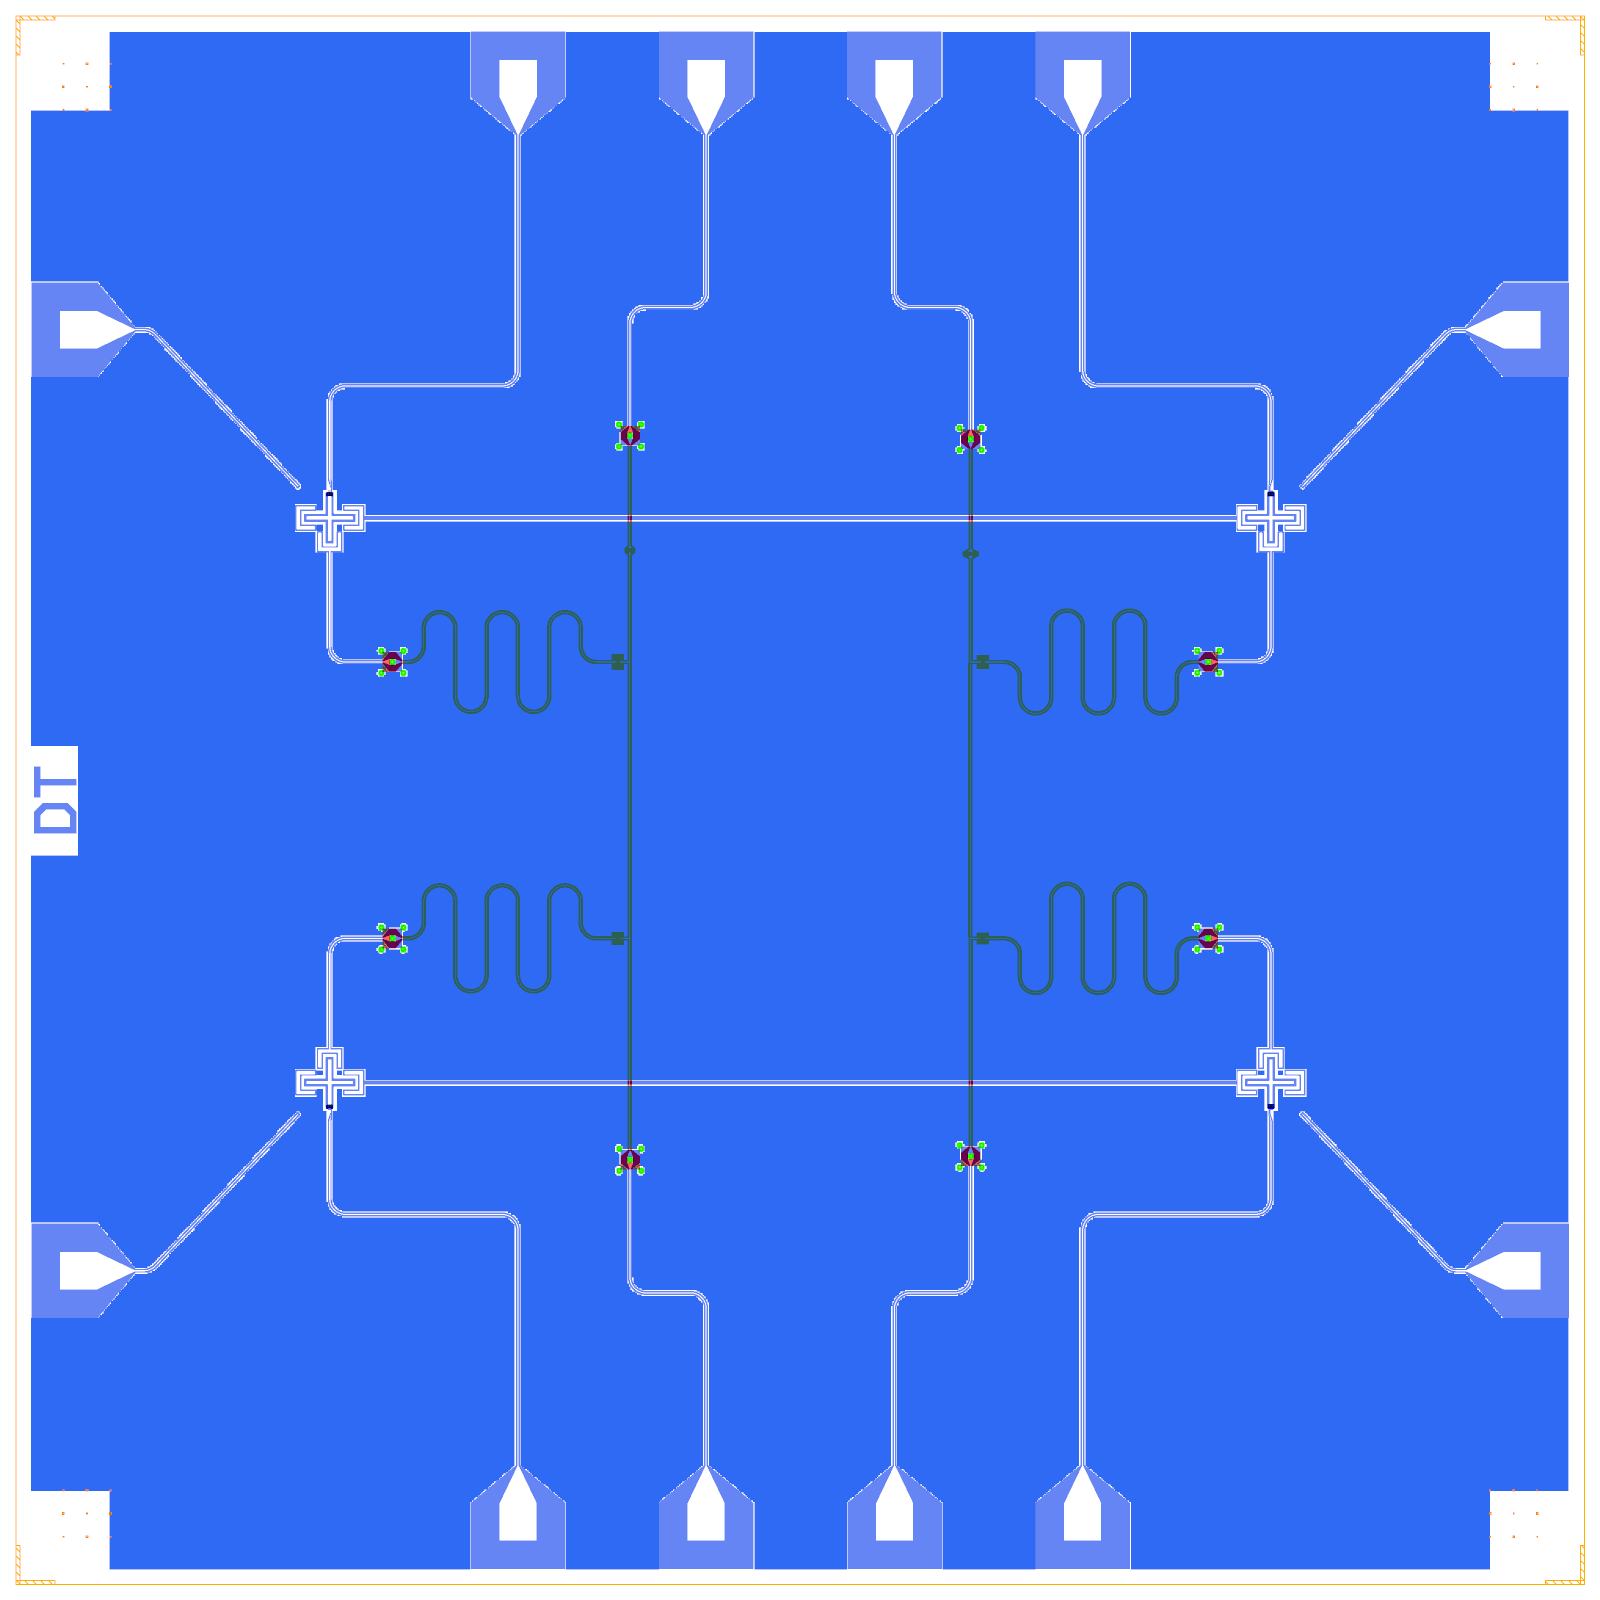

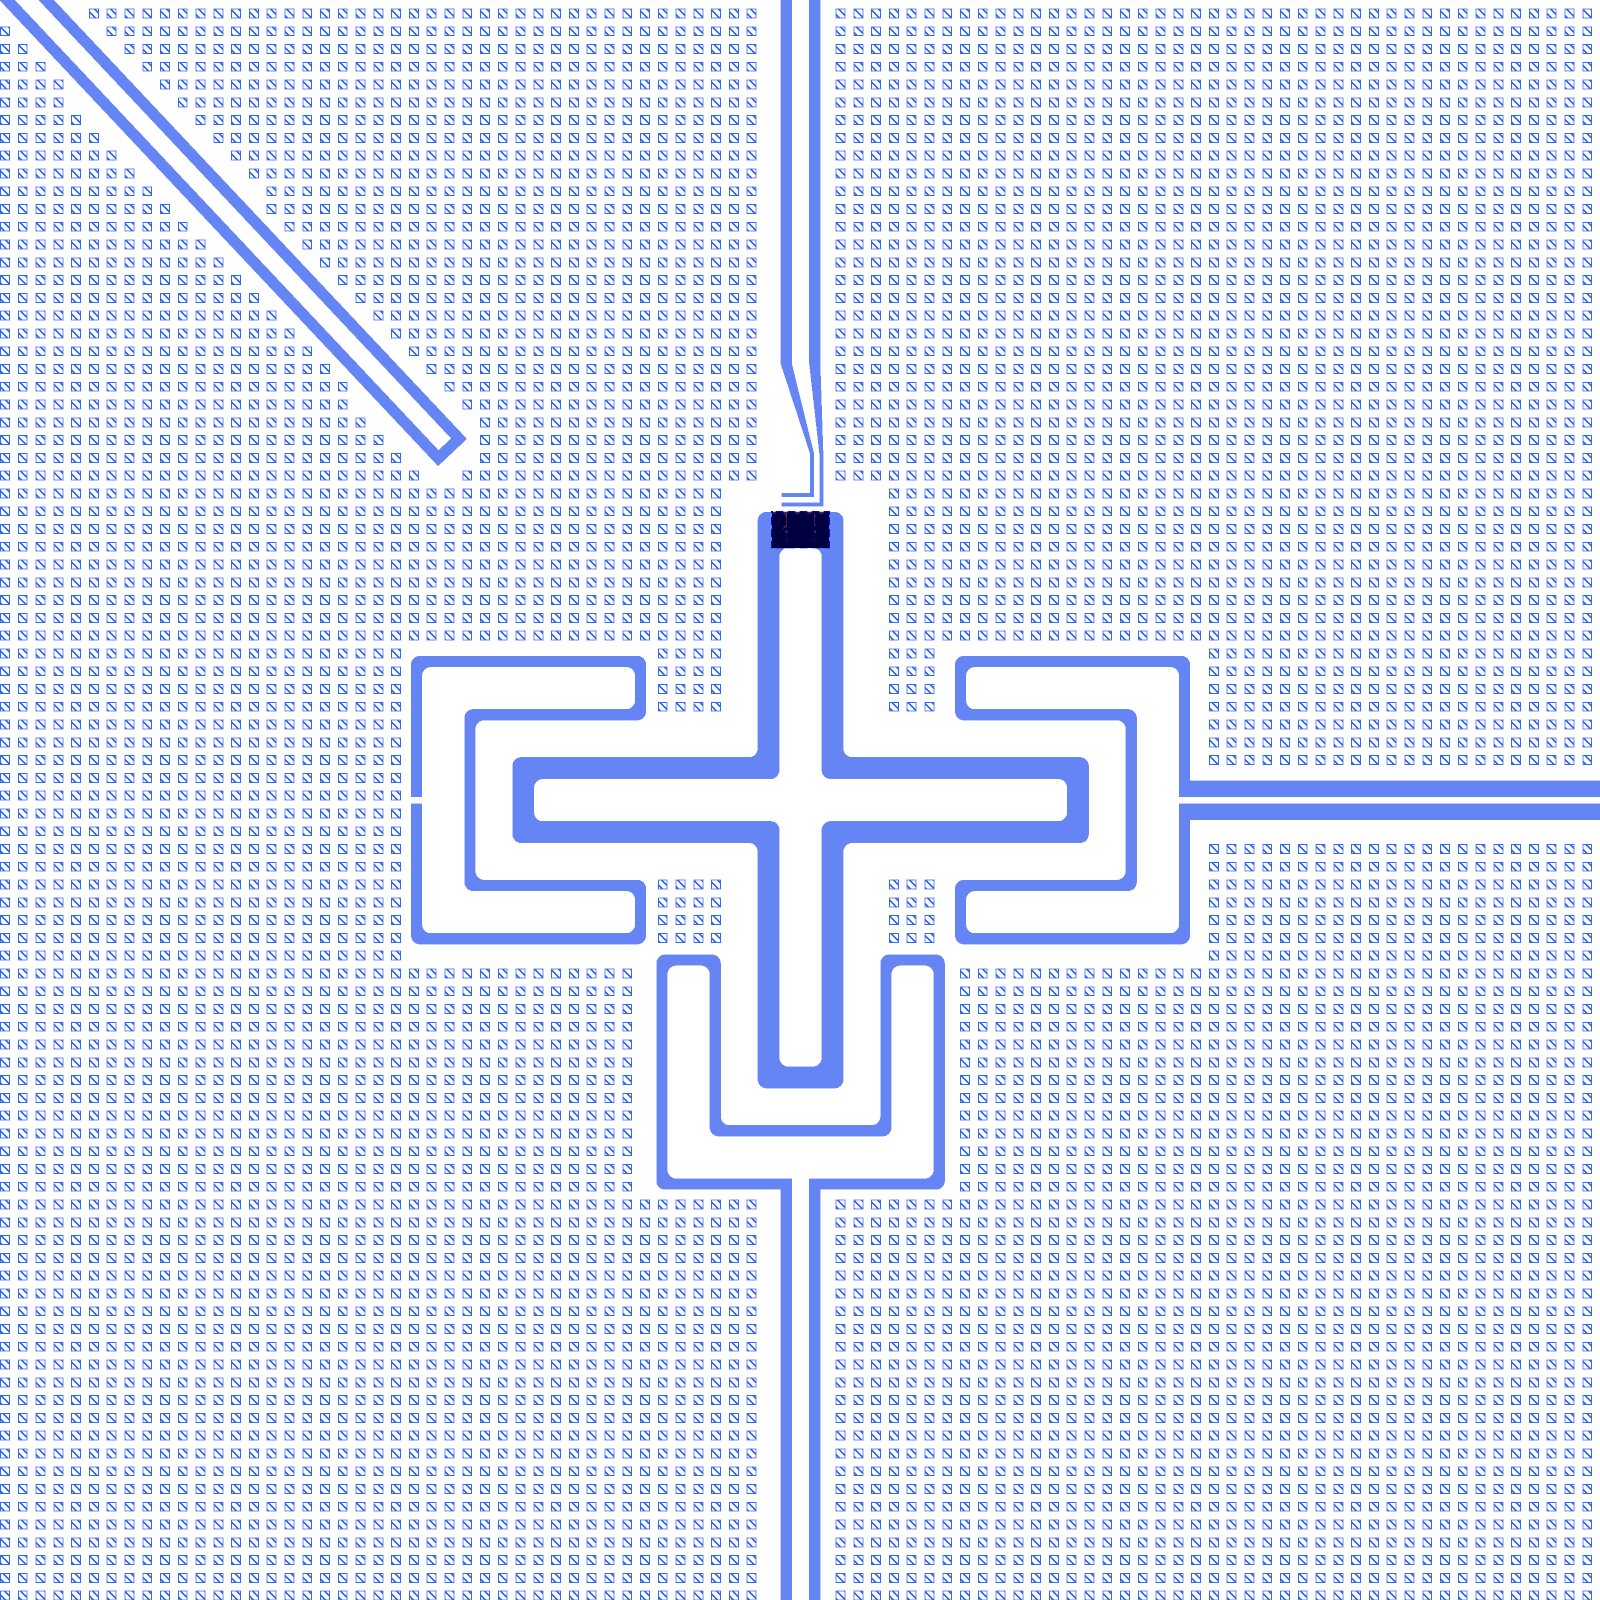

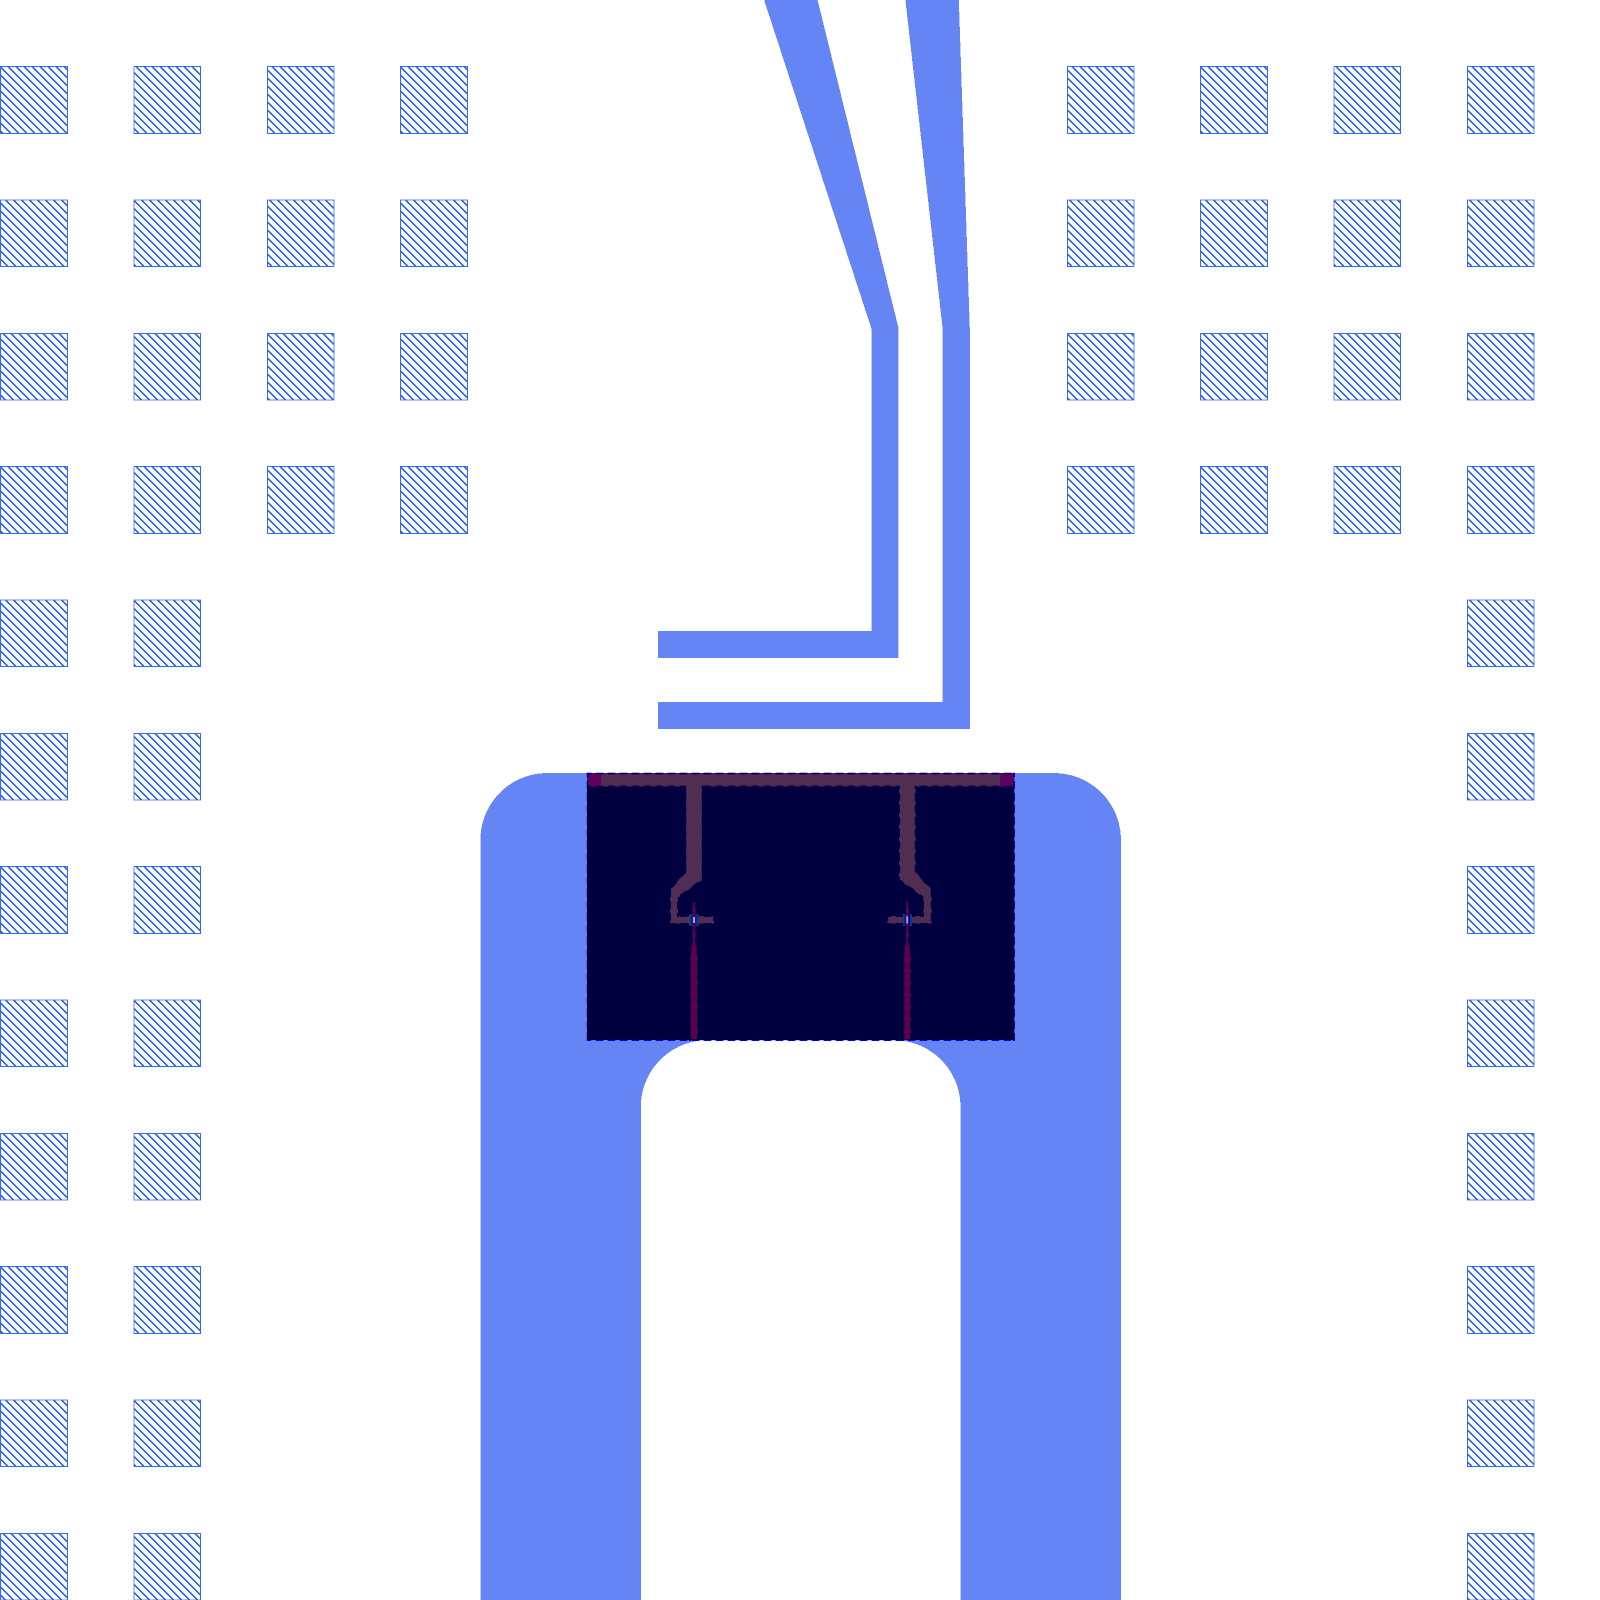

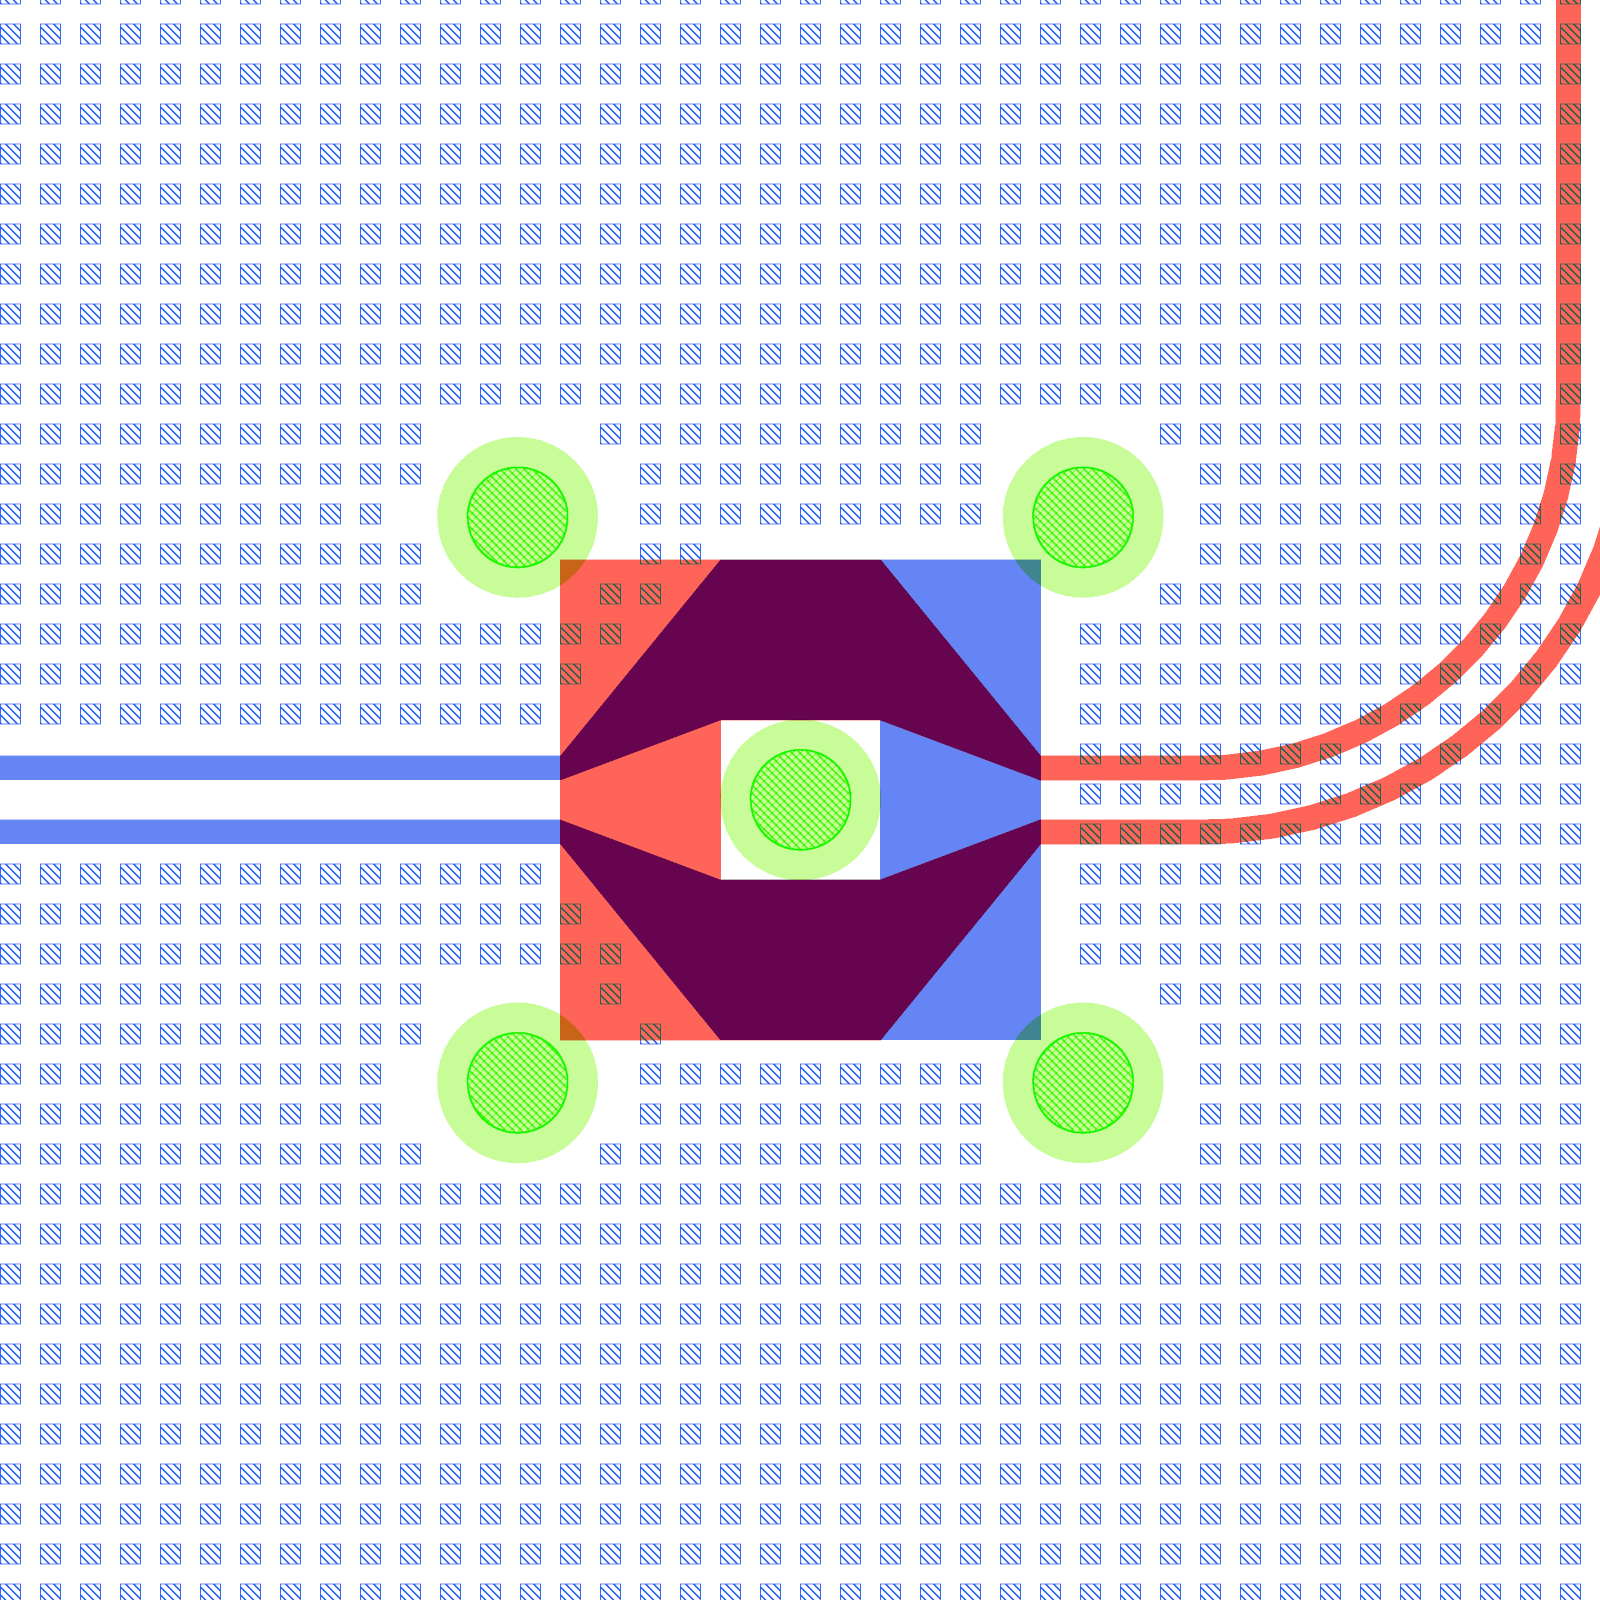

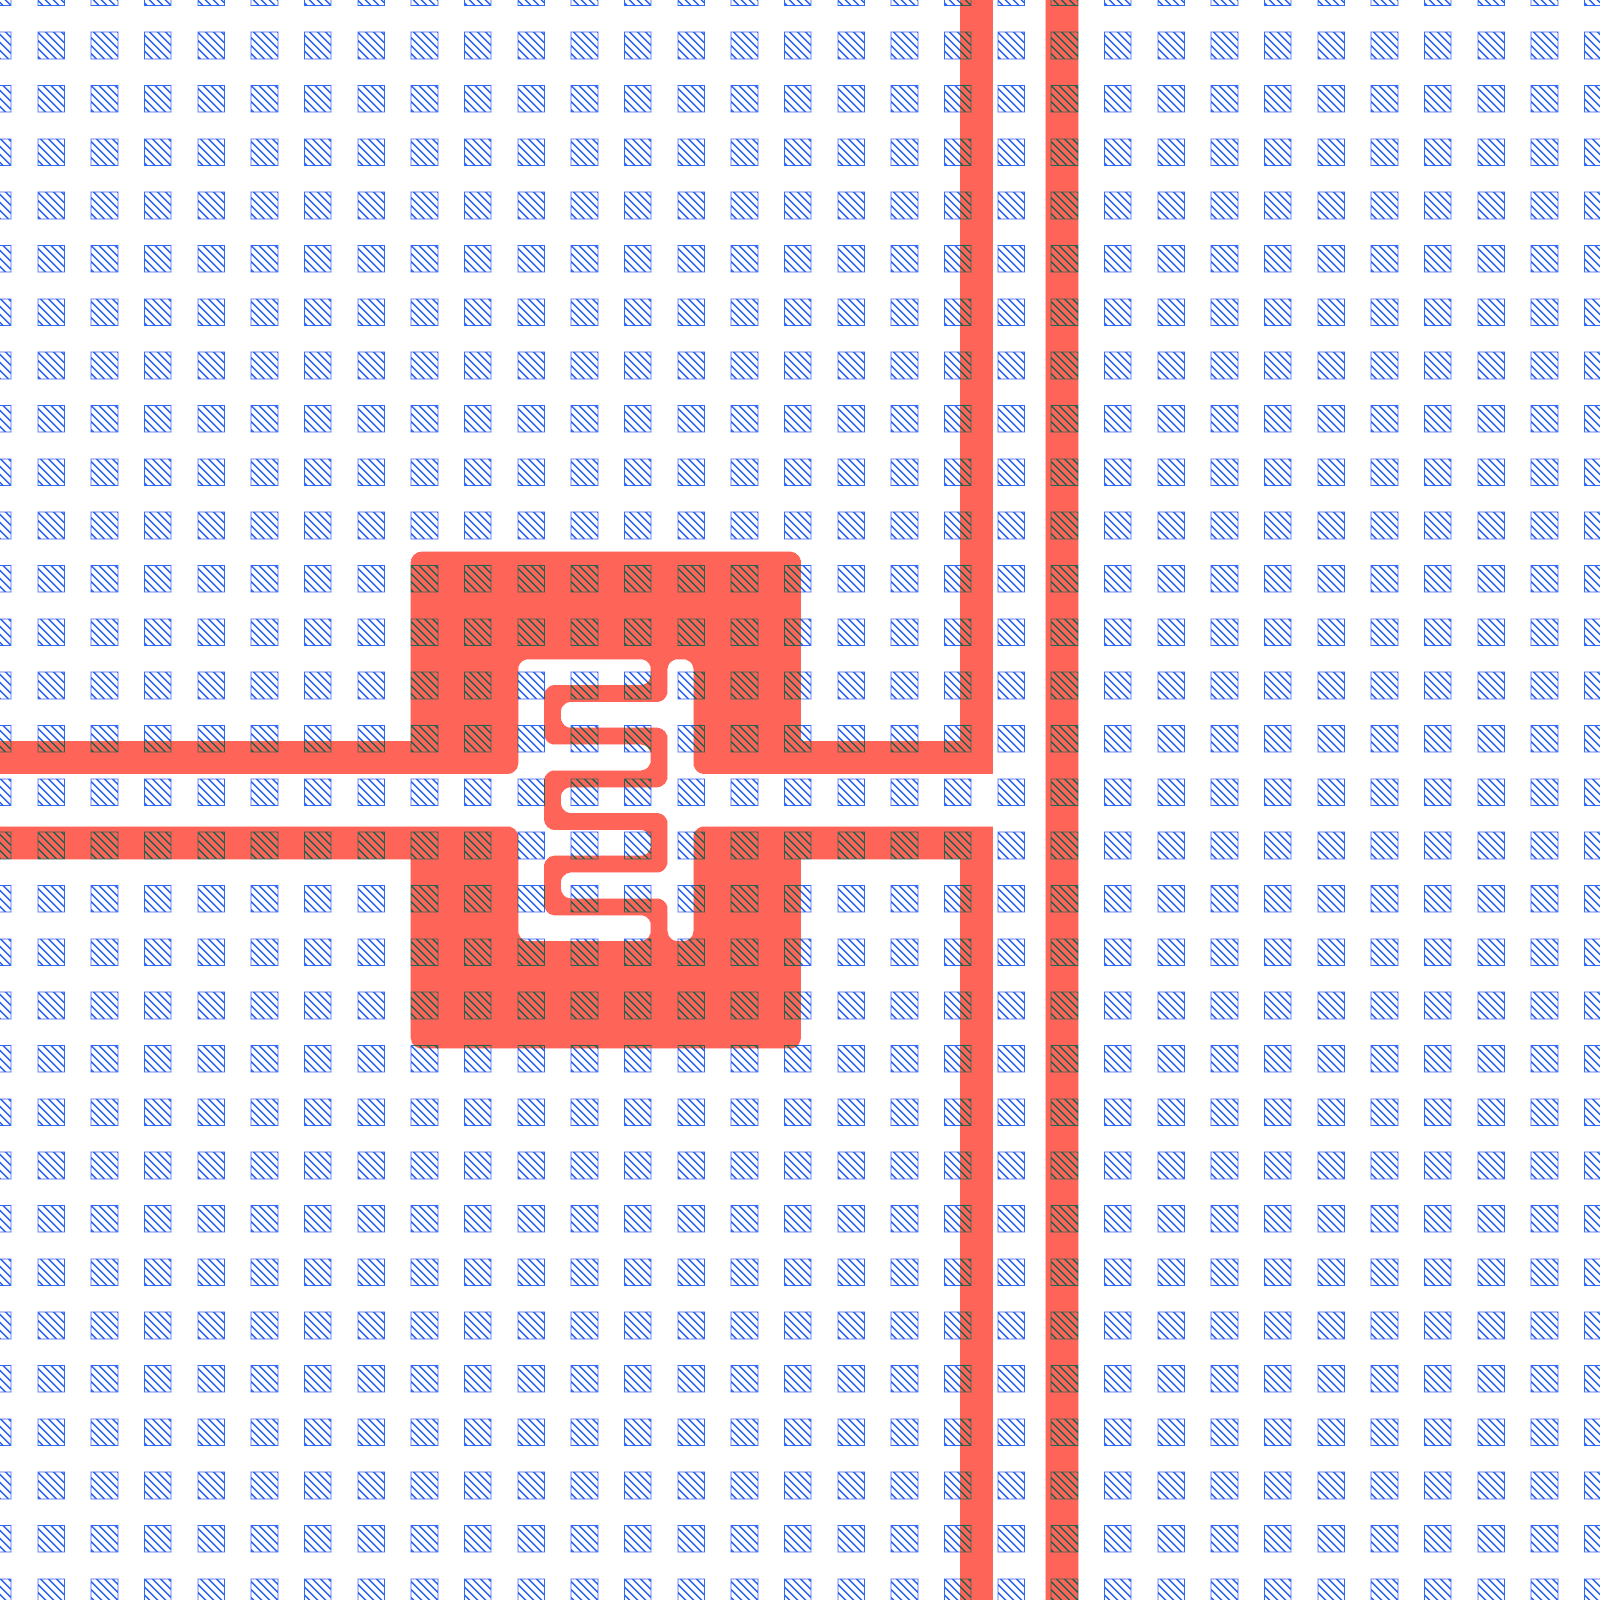

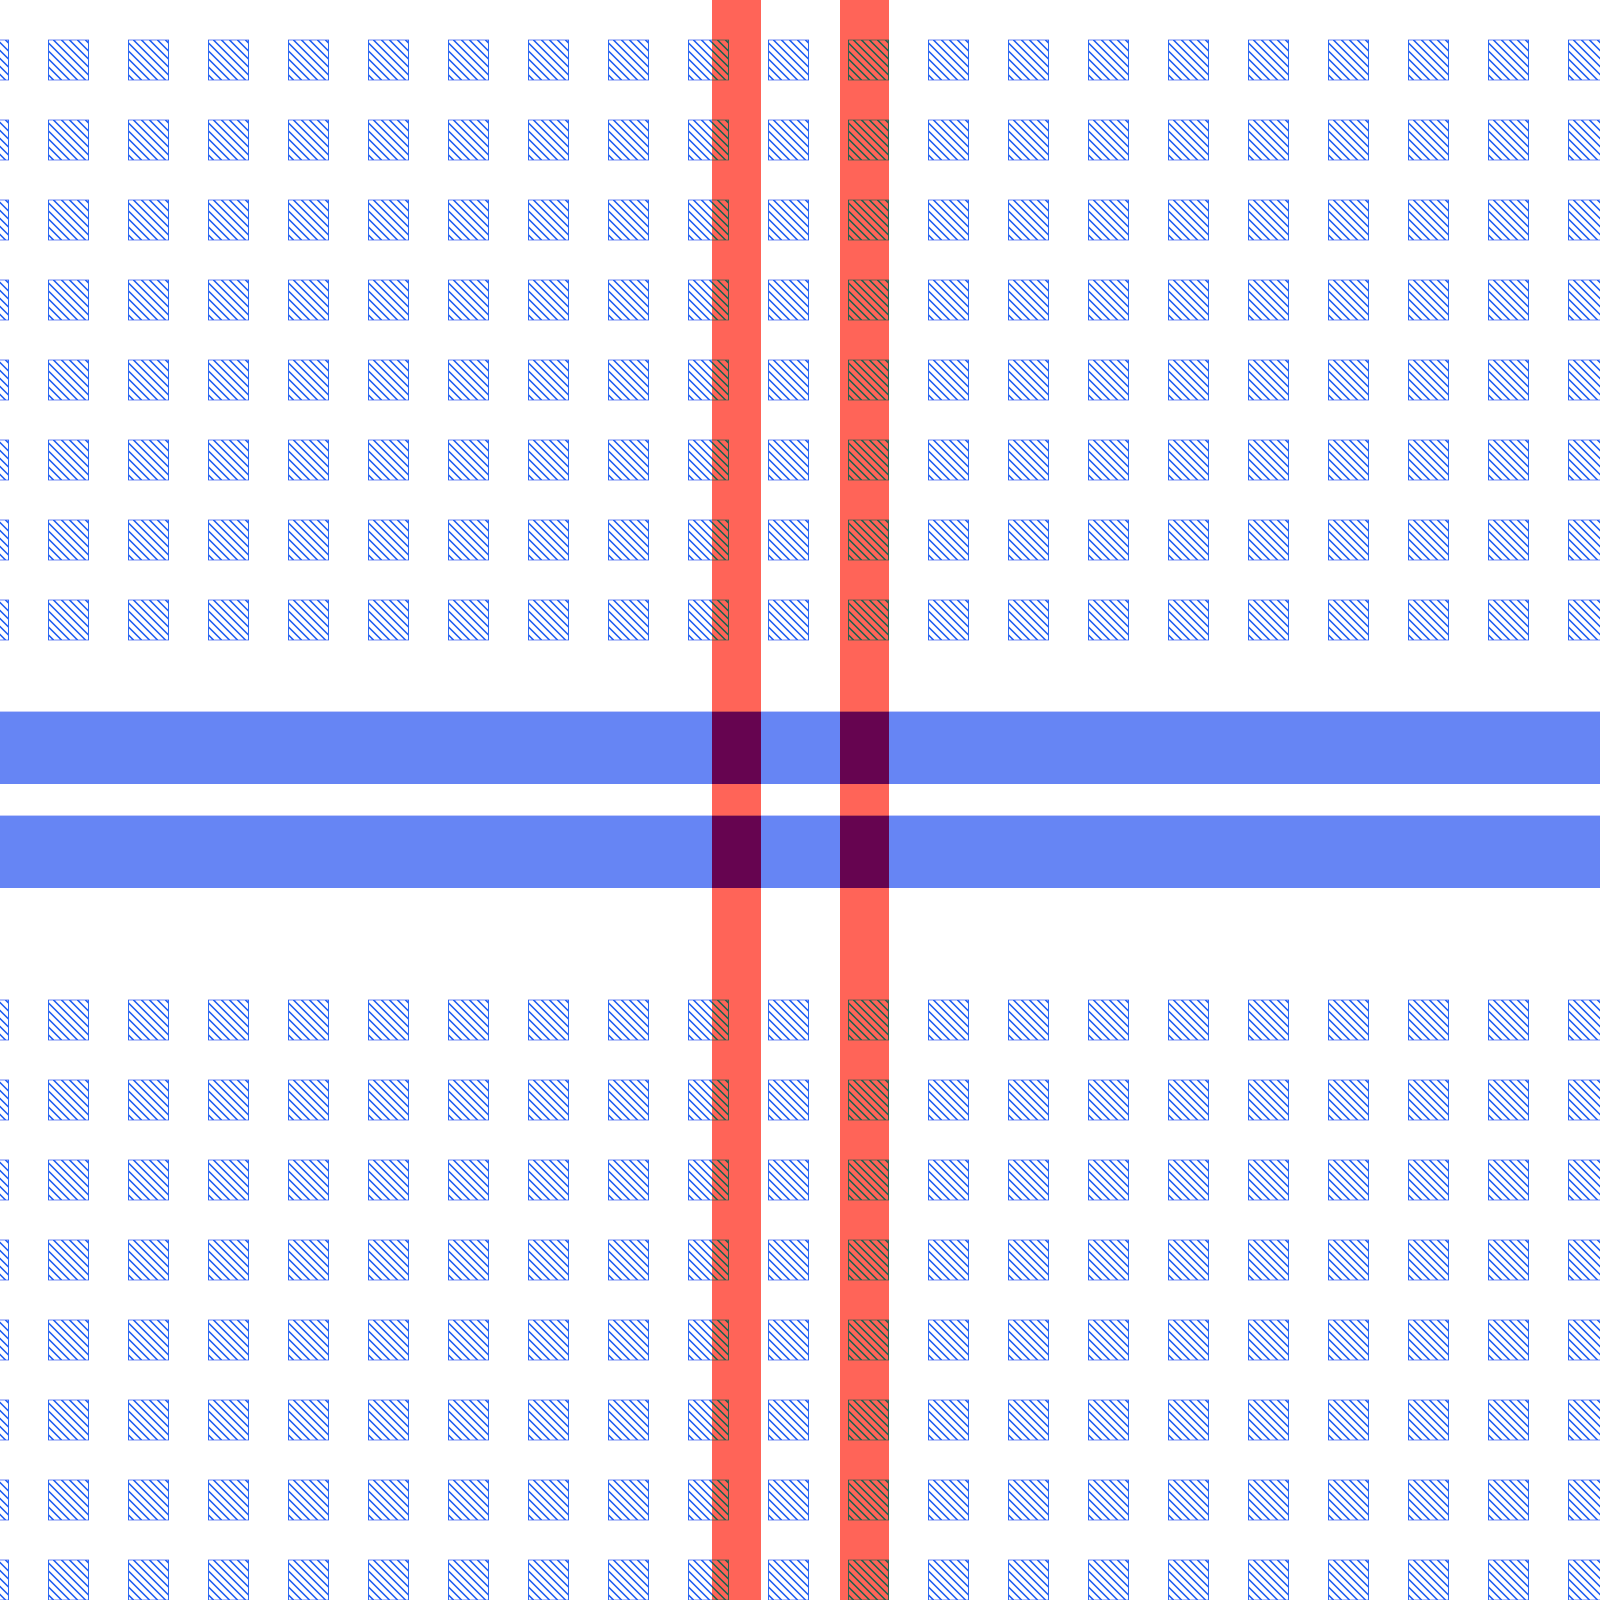

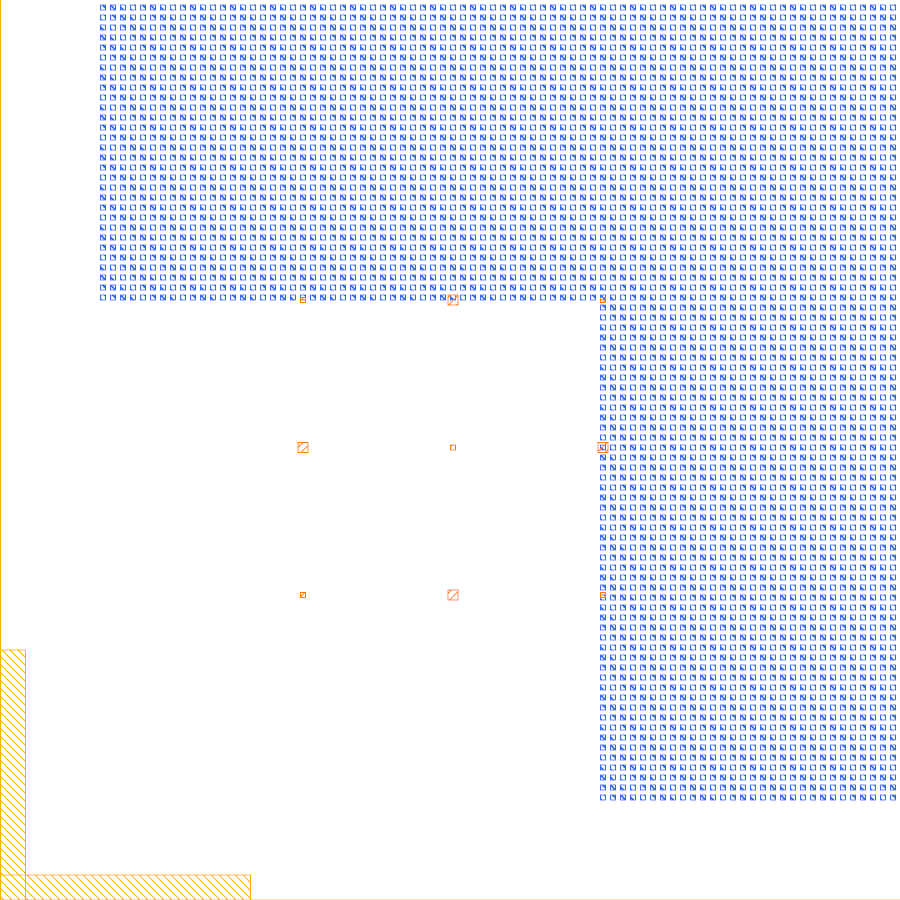

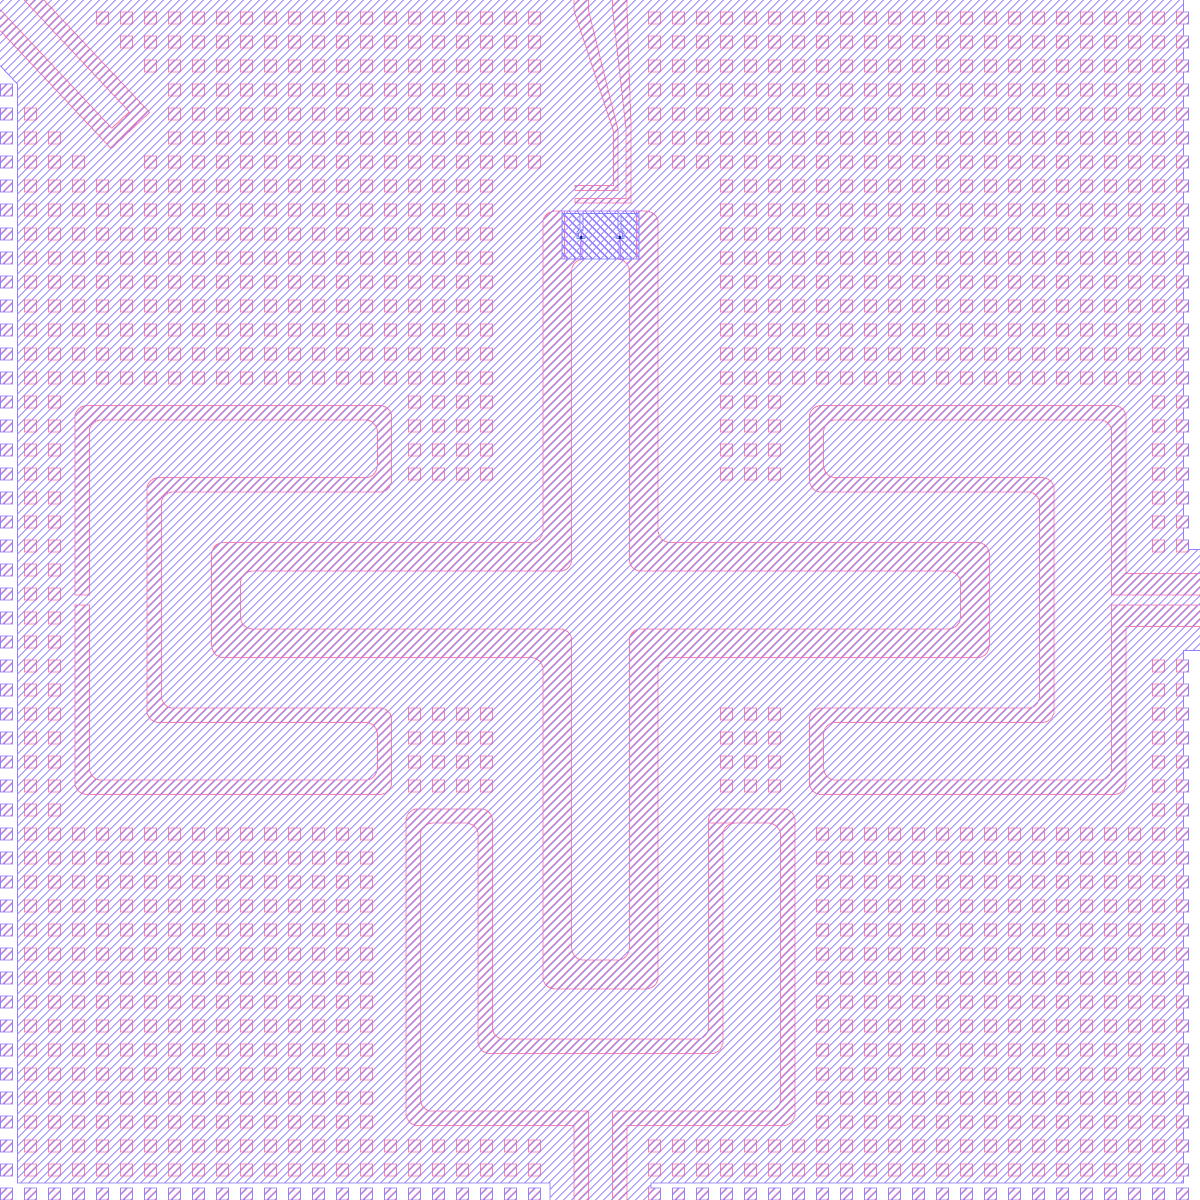

In [19]:
show_snapshot(d, OUT / "demo_twoface.png", box=(-100, -100, 10100, 10100))   # chip only (KQC launcher names outside)
qx, qy = base["QB1"][:2]
show_snapshot(d, OUT / "demo_twoface_qb1.png", box=(qx - 450, qy - 450, qx + 450, qy + 450), width=420)
show_snapshot(d, OUT / "demo_twoface_squid.png", box=(qx - 60, qy + 100, qx + 60, qy + 220), width=360)
x2, y2 = shift_away(xy("QB1.cplr1"), (qx, qy), 700)
show_snapshot(d, OUT / "demo_twoface_connector.png", box=(x2 + 200, y2 - 200, x2 + 600, y2 + 200), width=360)
cx, cy = xy("C1.b")
show_snapshot(d, OUT / "demo_twoface_coupler.png", box=(cx - 150, cy - 150, cx + 150, cy + 150), width=360)
show_snapshot(d, OUT / "demo_twoface_crossing.png", box=(3814, 6700, 4014, 6900), width=360)   # P1_in (top chip) over CPL12
show_snapshot(d, OUT / "demo_twoface_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "demo_twoface_fab.oas", OUT / "demo_twoface_fab_qb1.png",
          box=(qx - 250, qy - 250, qx + 250, qy + 250), size=(1200, 1200), width=420);

**The four bus crossings in the built geometry:** the probe line is on the top chip (2b1 gaps) and the bus
centre conductor on 1t1 is not cut (zero 1t1 gap area within ±2 µm of the bus centre line).

In [20]:
import klayout.db as kdb
ly = kdb.Layout(); ly.read(str(d.out)); top_d = ly.top_cell()
gap = {f: kdb.Region(top_d.begin_shapes_rec(next(i for i in ly.layer_indexes()
                                               if ly.get_info(i).name == f"{f}_base_metal_gap_wo_grid")))
       for f in ("1t1", "2b1")}
rows = ["| crossing (x, y) | 1t1 gap within ±2 µm of the bus centre (µm²) | 2b1 gap there (µm², the probe line) |",
        "|---|---|---|"]
for x, y in ((3914, 6800), (6086, 6800), (3914, 3200), (6086, 3200)):
    box = kdb.Region(kdb.Box(int((x - 30) / ly.dbu), int((y - 2) / ly.dbu), int((x + 30) / ly.dbu), int((y + 2) / ly.dbu)))
    rows.append(f"| ({x}, {y}) | {(gap['1t1'] & box).area() * ly.dbu ** 2:.0f} | {(gap['2b1'] & box).area() * ly.dbu ** 2:.0f} |")
display(Markdown("\n".join(rows)))

| crossing (x, y) | 1t1 gap within ±2 µm of the bus centre (µm²) | 2b1 gap there (µm², the probe line) |
|---|---|---|
| (3914, 6800) | 0 | 48 |
| (6086, 6800) | 0 | 48 |
| (3914, 3200) | 0 | 48 |
| (6086, 3200) | 0 | 48 |

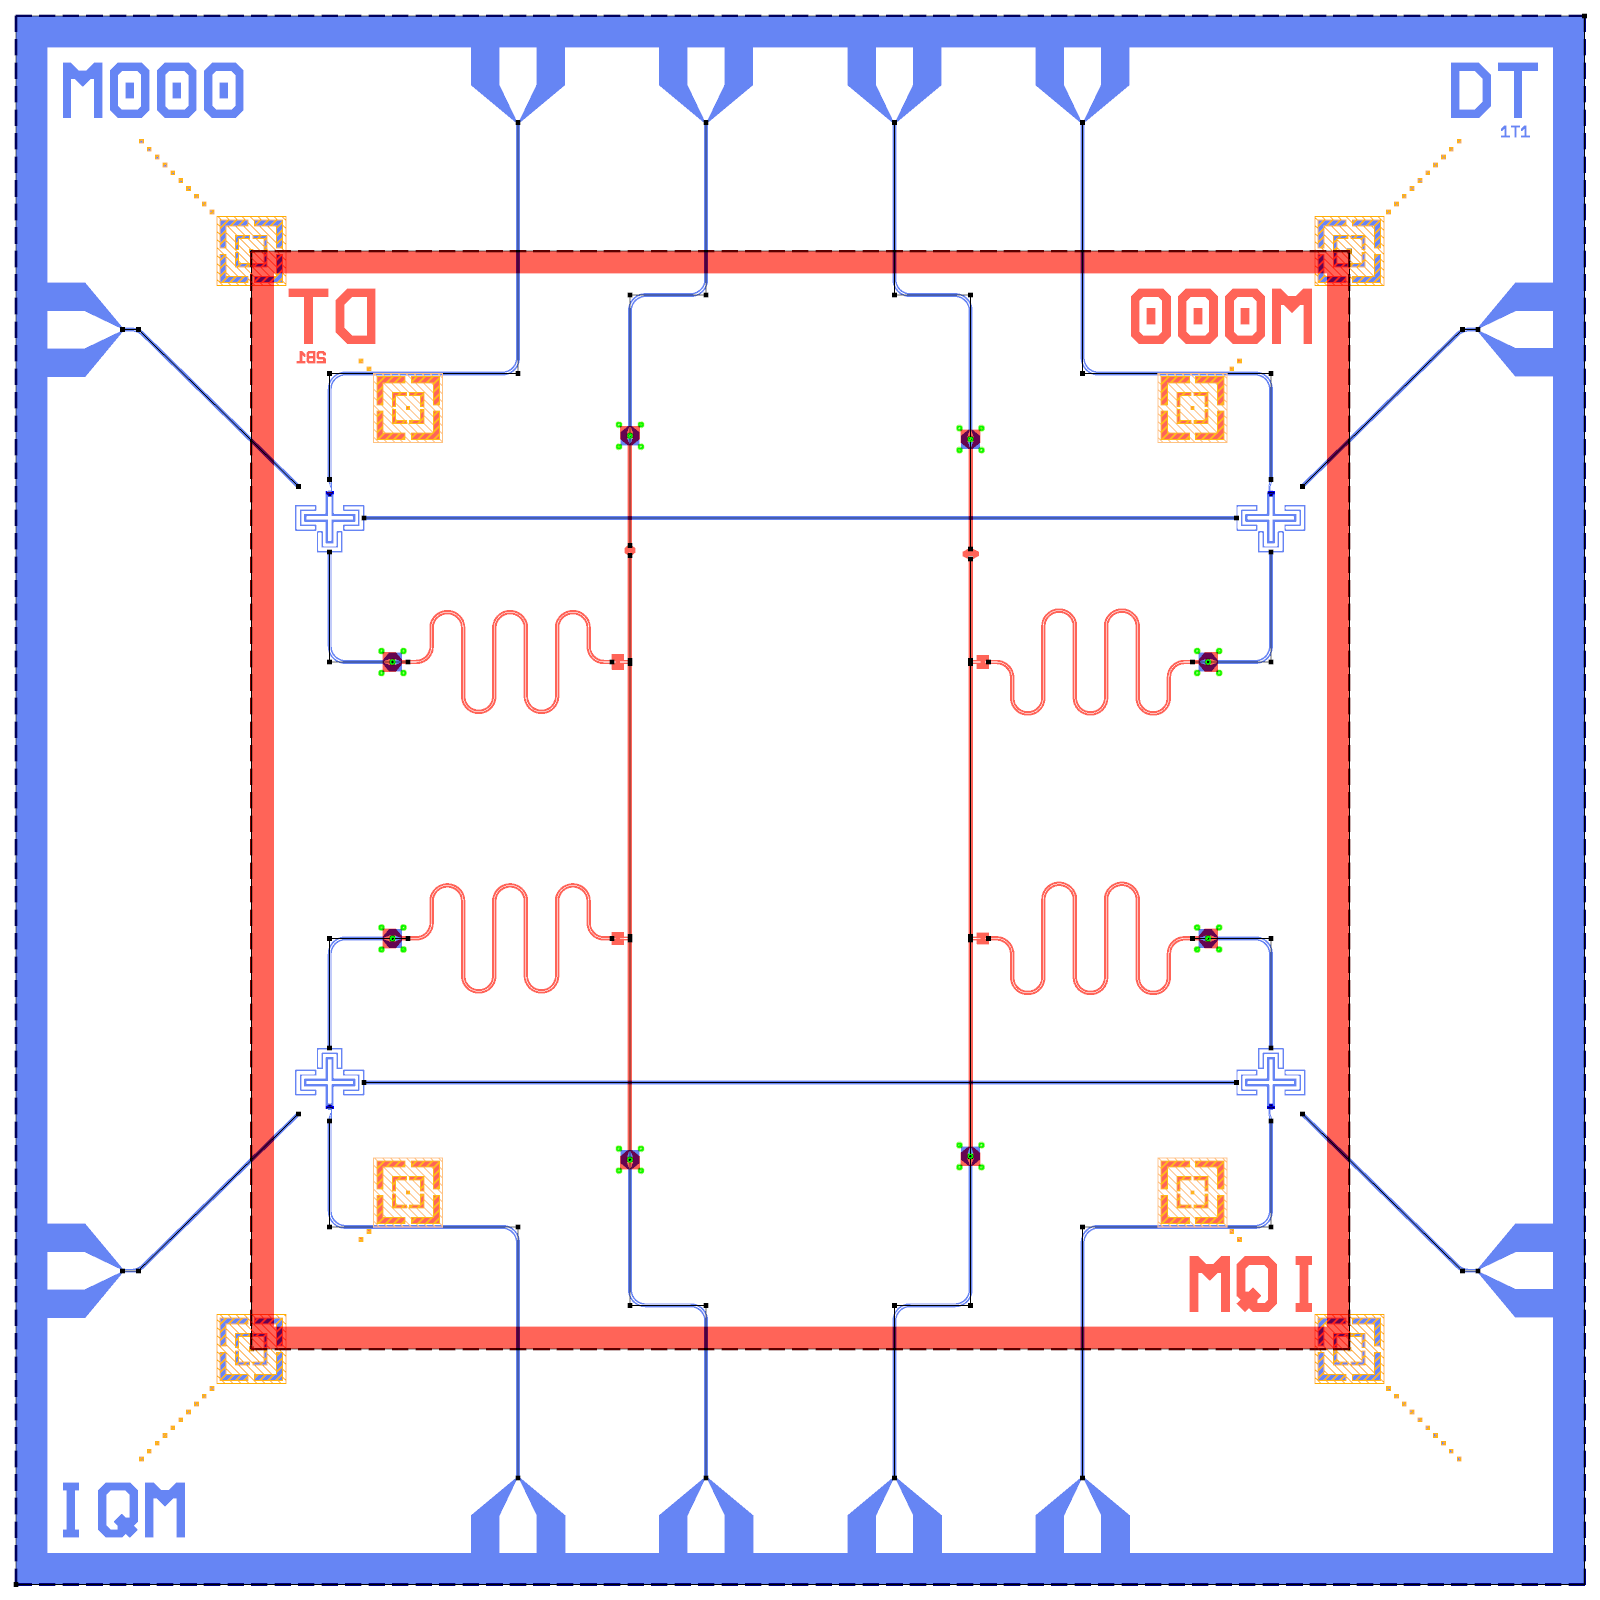

In [21]:
from kqcircuits.chips.demo_twoface import DemoTwoface
from kqcircuits.pya_resolver import pya

ref = pya.Layout()
top = ref.create_cell("kqc_demo_twoface")
top.insert(pya.DCellInstArray(DemoTwoface.create(ref).cell_index(), pya.DTrans()))
ref.write(str(Path("build") / "demo_twoface_kqc_original.oas"))
snap_file(Path("build") / "demo_twoface_kqc_original.oas", OUT / "demo_twoface_kqc.png", box=(-100, -100, 10100, 10100),
          width=420);

## 15 · Summary

| | |
|---|---|
| **matches the source** | every KQC element on both faces with its parameters, positions and orientations; the ARD24 launcher assignment; every route's path including the face changes and RF connectors; readout lengths 5000–5300 µm; the sim groups; KQC's whole-area ground grid (bottom chip) |
| **differs (PDK)** | Quantcore die frame on the bottom chip (none on the top chip: PDK v3 has no top-chip frame); launchers 79 µm further in (outer etch 100 µm from the edge, `frame.pad_edge`); sapphire; detuned Quantcore trilayer SQUIDs (f_q ≈ 6.0–5.7 GHz instead of ≈ 4.1–3.7 GHz); no grid on the top chip |
| **simplified** | router-fitted readout meanders |
| **PDK design warnings** | none (parallel R_n 41.7–46.9 kΩ; f_q 5.7–6.0 GHz) |
| **FEM** | 6 Q3D jobs exported (`build/jobs/demo_twoface_*`), not solved here |